# 중장년(5060) 1인 가구 사회적 고립 - EDA & 핵심 파생변수
- **분석 단위**: 행정동 (강남구 22 + 춘천시 25 = 47개 동)
- **사용 테이블**: DB 6개 (`SGG_MST`, `EMD_MST`, `POP_SEX_AGE`, `HH_SIZE`, `CARD_SPEND_TIME`, `CARD_SPEND_RESID`) + 월별 유동인구 3개 (`flow_age_monthly`, `flow_day_monthly`, `flow_time_monthly`)
- **목표**: 5060 고립 관련 특성을 확인하고, 동별 클러스터링(`modeling/Clustering.ipynb`)에 쓰는 핵심 파생변수 5개 생성 및 프로파일링

**클러스터링 입력 파생변수 (행정동 단위)**

| 축 | 파생변수 | 정의 | 위험 방향 | 출처 |
|---|---|---|---|---|
| 인구축 | 1-1 `HH1_EXPO_5060` | 1인 가구 비율 × 5060 인구 비중 | 높을수록 | HH_SIZE, POP_SEX_AGE |
| 인구축 | 1-2 `MALE_SHARE_5060` | 5060 인구 중 남성 비율 | 높을수록 | POP_SEX_AGE |
| 인구축 | 1-3 `VISIBLE_IDX_50P` | (유동인구 중 5060 비중) ÷ (주민 중 5060 비중) | **낮을수록** | flow_age_monthly, POP_SEX_AGE |
| 지역축 | 2-1 `TIME_ENTROPY` | 하루 유동인구의 시간대(0\~23시) 분포 엔트로피 | **낮을수록** | flow_time_monthly |
| 지역축 | 2-2 `POP_DENSITY` | 총인구 ÷ 면적(km²) | **낮을수록** | EMD_MST |

**카드 소비 지표 (EDA 전용, 시군구 단위)**: 5060 관계형 소비 비중 - 강남·춘천 × 성 × 연령 수준에서만 분석 (5장)

**유동인구 (EDA 전용, 행정동 × 월)**: 지역·동별 활동 리듬 확인 (6장)

## 0. 환경 설정

In [1]:
# Colab이면 드라이브 마운트, 로컬(VS Code 등)이면 건너뜀
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

In [2]:
if IN_COLAB:
    !apt-get -qq install -y fonts-nanum > /dev/null
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, PercentFormatter

if IN_COLAB:
    fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')   # 로컬은 설치된 나눔고딕 사용
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:,.3f}'.format)

In [3]:
# ---- 그래프 스타일 ----
# 색은 '대상'에 고정: 강남=파랑, 춘천=주황 / 남성=청록, 여성=보라 (노트북 전체에서 동일)
INK, INK2, MUTED, GRID, SURF, BAND = '#0b0b0b', '#52514e', '#8a8984', '#e6e5e1', '#fcfcfb', '#f0efec'
C = {'강남구': '#2a78d6', '춘천시': '#eb6834', '남성': '#1baf7a', '여성': '#4a3aa7'}
DIV = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efec', '#e34948'])   # 파랑-회색-빨강 (발산형)

plt.rcParams.update({
    'font.family': 'NanumGothic', 'axes.unicode_minus': False, 'figure.dpi': 110,
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF,
    'axes.edgecolor': '#c9c8c3', 'axes.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 26,
    'axes.titlecolor': INK, 'axes.labelcolor': INK2, 'axes.labelsize': 10,
    'xtick.color': INK2, 'ytick.color': INK2, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'legend.frameon': False, 'legend.fontsize': 9, 'lines.linewidth': 2, 'lines.markersize': 7,
})

def clean(ax, grid='y'):
    """한 방향 격자만 남기기"""
    ax.grid(axis='x' if grid == 'y' else 'y', visible=False)
    ax.tick_params(length=0)

def subtitle(ax, text):
    ax.text(0, 1.015, text, transform=ax.transAxes, fontsize=9, color=INK2, va='bottom')

pct = FuncFormatter(lambda v, _: f'{v:.0%}')

In [4]:
if IN_COLAB:
    DB = Path('/content/drive/MyDrive/빅콘/DATA/DB')
else:   # 로컬(VS Code 등): 노트북 폴더에서 위로 올라가며 저장소 루트(Knock-Model/)를 찾음
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / '.gitignore').exists())
    DB = ROOT / 'database'

# 코드 컬럼은 문자열로 읽기 (join 키 형식 유지)
code = {'SGG_CD': str, 'EMD_CD': str, 'TA_YMD': str}
read = lambda name: pd.read_csv(DB / f'{name}.csv', dtype=code, encoding='utf-8-sig')

sgg_mst     = read('SGG_MST')            # 시군구 (2)
emd_mst     = read('EMD_MST')            # 행정동 (47)
pop_sex_age = read('POP_SEX_AGE')        # 행정동 × 성별 × 연령
hh_size     = read('HH_SIZE')            # 행정동 × 세대원수
card_time   = read('CARD_SPEND_TIME')    # 일자 × 시간대 × 업종 × 성별 × 연령 (가맹점 시군구 단위)
card_resid  = read('CARD_SPEND_RESID')   # 일자 × 업종 × 고객거주 시도 × 성별 × 연령 (가맹점 시군구 단위)

tables = {'SGG_MST': sgg_mst, 'EMD_MST': emd_mst, 'POP_SEX_AGE': pop_sex_age,
          'HH_SIZE': hh_size, 'CARD_SPEND_TIME': card_time, 'CARD_SPEND_RESID': card_resid}

# 공통 상수
SGG_NM    = dict(zip(sgg_mst.SGG_CD, sgg_mst.SGG_NM))     # {'11230': '강남구', '32010': '춘천시'}
REGIONS   = ['강남구', '춘천시']
LOCAL     = {'11230': '서울', '32010': '강원'}              # 가맹점 시군구 → 거주민으로 볼 고객 시도
T5060     = ['50대', '60대']
AGE_ORDER = ['10대미만', '10대', '20대', '30대', '40대', '50대', '60대', '70대', '80대', '90대', '100세이상']
CARD_AGE  = ['10대', '20대', '30대', '40대', '50대', '60대', '70대', '80대', '90대']
AGE_GRP   = {'10대': '10대', '20대': '2040', '30대': '2040', '40대': '2040',
             '50대': '5060', '60대': '5060', '70대': '70+', '80대': '70+', '90대': '70+'}
GRP_ORDER = ['10대', '2040', '5060', '70+']

## 1. 데이터 품질 확인

In [5]:
pd.DataFrame({name: {'rows': len(df), 'cols': df.shape[1],
                     '결측치': int(df.isna().sum().sum()), '중복행': int(df.duplicated().sum())}
              for name, df in tables.items()}).T

,rows,cols,결측치,중복행
SGG_MST,2,2,0,0
EMD_MST,47,5,0,0
POP_SEX_AGE,1034,4,0,0
HH_SIZE,470,3,0,0
CARD_SPEND_TIME,1044710,9,0,0
CARD_SPEND_RESID,1806800,9,0,0


In [6]:
for name, df in [('CARD_SPEND_TIME', card_time), ('CARD_SPEND_RESID', card_resid)]:
    print(f'{name}: {df.TA_YMD.min()} ~ {df.TA_YMD.max()} ({df.TA_YMD.nunique()}일), '
          f'업종 {df.MCT_RY_CD.nunique()}개, 가맹점 시군구 {df.SGG_CD.nunique()}개')

CARD_SPEND_TIME: 20250701 ~ 20251231 (184일), 업종 91개, 가맹점 시군구 2개


CARD_SPEND_RESID: 20250701 ~ 20251231 (184일), 업종 90개, 가맹점 시군구 2개


**📌 해석**
- 6개 테이블 모두 **결측치·중복 행 없음** → 별도 정제 없이 분석 가능
- 카드 데이터는 2025-07-01 \~ 12-31 **184일, 빠진 날 없음** (추석 연휴 10/3\~10/9 포함)
- ⚠️ 카드 데이터의 지역 단위는 **가맹점이 있는 시군구(2개)** 뿐이다. 동 정보가 없으므로, 카드 지표는 **강남·춘천 시군구 단위로만 분석**하고 동별 클러스터링에는 넣지 않는다 (→ 5장)

## 2. 지역 기본 구조 (행정동)

In [7]:
H = hh_size.pivot_table(index='EMD_CD', columns='HH_SIZE_CCD', values='HH_CNT', aggfunc='sum')
P = pop_sex_age.pivot_table(index='EMD_CD', columns=['SEX_CCD', 'AGE_CCD'], values='POP_CNT', aggfunc='sum')
tot = P.sum(axis=1)
p5060 = P.loc[:, (slice(None), T5060)].sum(axis=1)

emd = emd_mst.set_index('EMD_CD').copy()
emd['SGG_NM']      = emd.SGG_CD.map(SGG_NM)
emd['POP_DENSITY'] = emd.TOT_POP_CNT / emd.AREA_KM2
emd['HH1_RATIO']   = H['1인'] / H.sum(axis=1)
emd['RATIO_5060']  = p5060 / tot
emd['RATIO_60P']   = P.loc[:, (slice(None), AGE_ORDER[6:])].sum(axis=1) / tot

(emd.groupby('SGG_NM')[['TOT_POP_CNT', 'POP_DENSITY', 'HH1_RATIO', 'RATIO_5060', 'RATIO_60P']]
    .agg(['min', 'median', 'max']).T)

SGG_NM                    강남구        춘천시
TOT_POP_CNT min    12,689.000    935.000
            median 23,368.000  6,869.000
            max    45,955.000 45,434.000
POP_DENSITY min     6,540.722      4.350
            median 15,358.309  2,169.304
            max    31,458.824 18,535.616
HH1_RATIO   min         0.076      0.327
            median      0.370      0.451
            max         0.745      0.737
RATIO_5060  min         0.218      0.263
            median      0.281      0.327
            max         0.335      0.511
RATIO_60P   min         0.152      0.259
            median      0.236      0.321
            max         0.489      0.742

**📌 해석**
- 두 지역은 구조가 크게 다르다
  - **인구밀도**: 강남 동 중앙값 약 15,000명/km² vs 춘천 약 2,200명/km² (북산면은 4명/km²)
  - **5060 비중**: 강남 22\~34% vs 춘천 26\~51% → 춘천 면 지역은 주민 절반이 5060
  - **1인 가구 비율**: 강남 8\~75%, 춘천 33\~74% → 두 지역 모두 동 간 편차가 매우 큼
- 👉 원값을 그대로 섞어 군집하면 "강남 vs 춘천"으로만 갈린다. 파생변수는 **시군구 안에서 표준화**해서 써야 한다

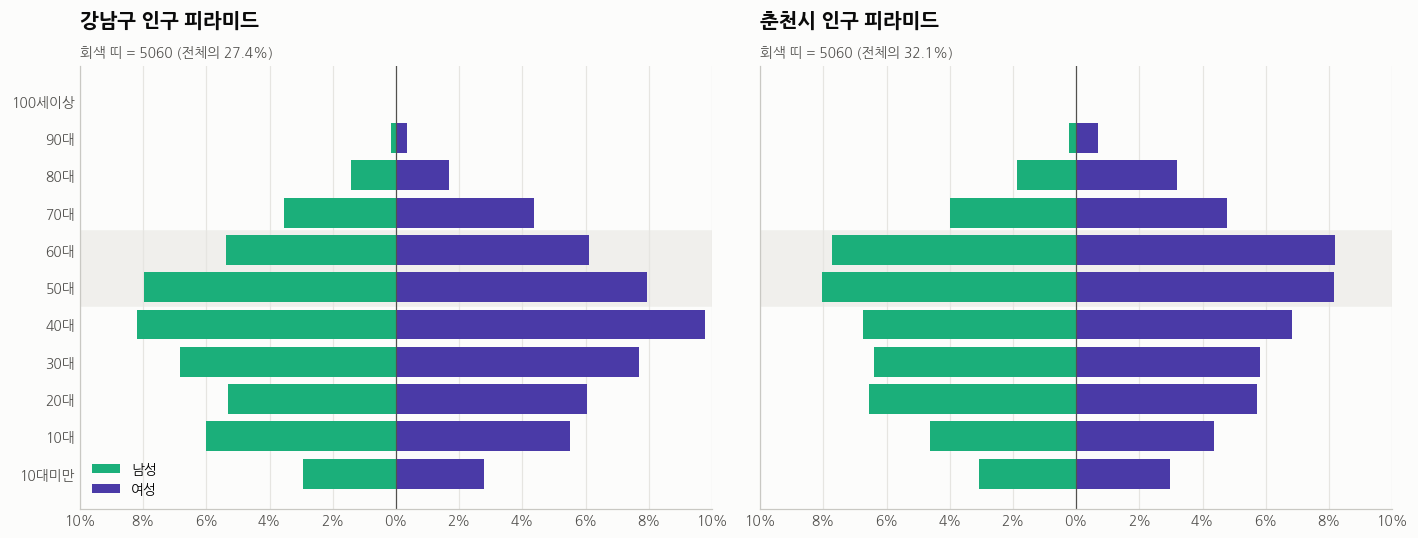

In [8]:
# 인구 피라미드 (%) - 5060 구간 강조
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, nm in zip(axes, REGIONS):
    g = pop_sex_age[pop_sex_age.EMD_CD.str[:5].map(SGG_NM) == nm]
    t = g.pivot_table(index='AGE_CCD', columns='SEX_CCD', values='POP_CNT', aggfunc='sum').reindex(AGE_ORDER)
    t = t / t.values.sum()
    y = np.arange(len(AGE_ORDER))
    for a in T5060:
        ax.axhspan(AGE_ORDER.index(a) - 0.5, AGE_ORDER.index(a) + 0.5, color=BAND, zorder=0)
    ax.barh(y, -t['남성'], height=0.8, color=C['남성'], label='남성')
    ax.barh(y,  t['여성'], height=0.8, color=C['여성'], label='여성')
    ax.axvline(0, color=INK2, lw=0.8)
    ax.set_yticks(y, AGE_ORDER)
    ax.set_xlim(-0.1, 0.1)
    ax.set_xticks(np.arange(-0.1, 0.101, 0.02))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{abs(v):.0%}'))
    s5060 = t.loc[T5060].values.sum()
    ax.set_title(f'{nm} 인구 피라미드')
    subtitle(ax, f'회색 띠 = 5060 (전체의 {s5060:.1%})')
    clean(ax, grid='x')
axes[0].legend(loc='lower left')
plt.tight_layout(); plt.show()

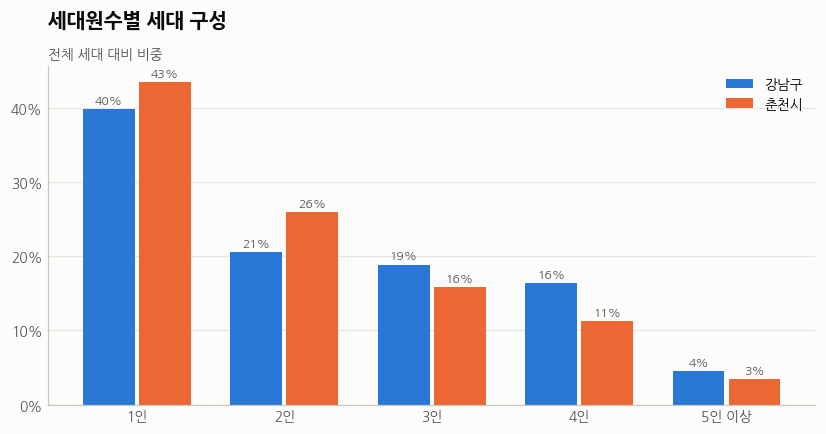

In [9]:
# 세대원수 구성 비교
HH_ORDER = [f'{i}인' for i in range(1, 10)] + ['10인이상']
hh_c = (hh_size.assign(SGG_NM=hh_size.EMD_CD.str[:5].map(SGG_NM))
               .pivot_table(index='HH_SIZE_CCD', columns='SGG_NM', values='HH_CNT', aggfunc='sum')
               .reindex(HH_ORDER).pipe(lambda t: t / t.sum()))
show = hh_c.loc[['1인', '2인', '3인', '4인']].copy()
show.loc['5인 이상'] = hh_c.loc[HH_ORDER[4:]].sum()

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(show)); w = 0.38
for i, nm in enumerate(REGIONS):
    bars = ax.bar(x + (i - 0.5) * w, show[nm], width=w - 0.03, color=C[nm], label=nm)
    ax.bar_label(bars, labels=[f'{v:.0%}' for v in show[nm]], padding=2, fontsize=8, color=INK2)
ax.set_xticks(x, show.index); ax.yaxis.set_major_formatter(pct)
ax.set_title('세대원수별 세대 구성'); subtitle(ax, '전체 세대 대비 비중')
ax.legend(); clean(ax); plt.show()

**📌 해석**
- 인구 피라미드: 5060이 전체 인구에서 차지하는 비중은 **강남 27.4%, 춘천 32.1%**. 춘천은 50·60대가 가장 두꺼운 연령층이다
- 세대 구성: 1인 가구가 가장 흔한 가구 형태 (**강남 40%, 춘천 43%**). 춘천은 1\~2인 가구가 70%에 달함
- ⚠️ `HH_SIZE`에는 **가구주 연령이 없다** → "5060 1인 가구 수"를 직접 알 수 없으므로 동 단위 비율 결합으로 근사한다 (→ 파생변수 ①)

## 3. 5060 인구 구조와 1인 가구

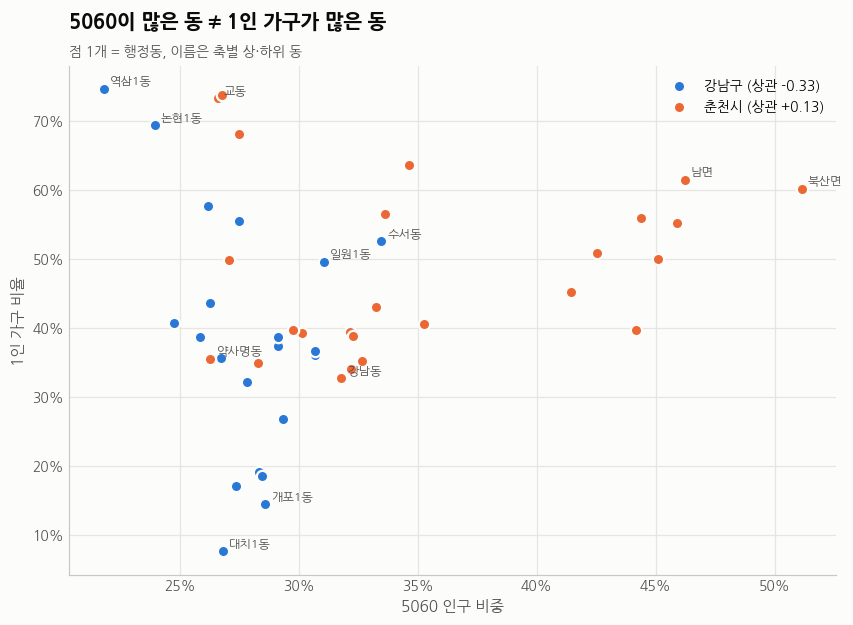

In [10]:
def label_extremes(ax, g, xcol, ycol, n=3, scale=1):
    """축별 상·하위 n개 동만 이름 표시 (가까운 점끼리는 하나만 표시해 겹침 방지)"""
    idx = list(dict.fromkeys(list(g.nlargest(n, xcol).index) + list(g.nsmallest(n, xcol).index) +
                             list(g.nlargest(n, ycol).index) + list(g.nsmallest(n, ycol).index)))
    xr = np.ptp(g[xcol]) or 1; yr = np.ptp(g[ycol]) or 1
    placed = getattr(ax, '_placed', [])
    for i in idx:
        x, y = g.at[i, xcol], g.at[i, ycol]
        if any(abs(x - px) / xr < 0.08 and abs(y - py) / yr < 0.06 for px, py in placed):
            continue
        placed.append((x, y)); ax._placed = placed
        ax.annotate(g.at[i, 'EMD_NM'], (x * scale, y * scale),
                    xytext=(4, 3), textcoords='offset points', fontsize=8, color=INK2)

fig, ax = plt.subplots(figsize=(9, 6))
for nm in REGIONS:
    g = emd[emd.SGG_NM == nm]
    r = g.RATIO_5060.corr(g.HH1_RATIO)
    ax.scatter(g.RATIO_5060, g.HH1_RATIO, s=55, color=C[nm], edgecolor=SURF, linewidth=1.5,
               label=f'{nm} (상관 {r:+.2f})', zorder=3)
    label_extremes(ax, g, 'RATIO_5060', 'HH1_RATIO', n=2)
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_xlabel('5060 인구 비중'); ax.set_ylabel('1인 가구 비율')
ax.set_title('5060이 많은 동 ≠ 1인 가구가 많은 동'); subtitle(ax, '점 1개 = 행정동, 이름은 축별 상·하위 동')
ax.legend(loc='upper right'); ax.tick_params(length=0); plt.show()

**📌 해석**
- 동 단위로 보면 5060 비중과 1인 가구 비율의 상관이 **강남 −0.33, 춘천 +0.13**으로 약하다 → 두 값은 서로 다른 정보
- 1인 가구 비율 최상위 동(역삼1동·논현1동·교동·효자2동)은 5060 비중이 낮은 **청년 1인 가구 밀집지**(오피스·대학가)
- 반대로 춘천 북산면·남면은 **5060 비중과 1인 가구 비율이 모두 높은** 곳 → 우리가 찾는 중장년 1인 가구 고위험 후보
- 👉 1인 가구 비율 하나로는 5060 1인 가구를 잡지 못한다 → 두 비율을 곱한 **파생변수 ①** 의 근거

## 4. 카드 소비 - 분석 범위 정하기

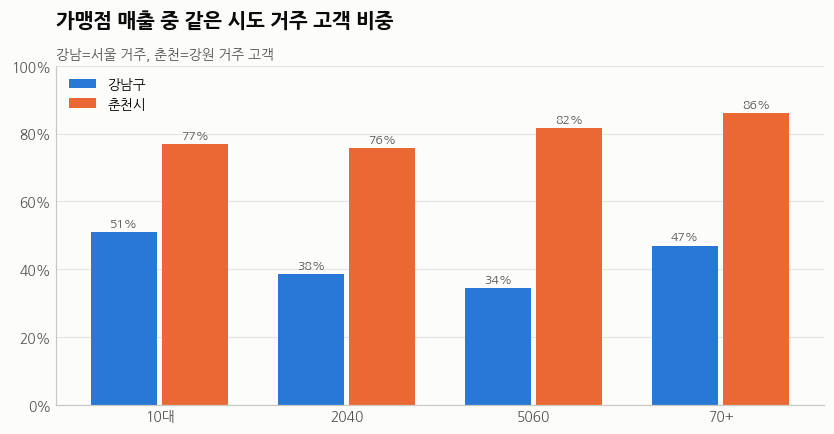

법인 매출 비중: {'강남구': '16.1%', '춘천시': '13.1%'}


In [11]:
# 연령 그룹별 '같은 시도 거주 고객' 매출 비중
card_resid['AGE_GRP']  = card_resid.AGE_CCD.map(AGE_GRP)
card_resid['IS_LOCAL'] = card_resid.CLN_SGG_CD == card_resid.SGG_CD.map(LOCAL)
lc = card_resid.pivot_table(index=['SGG_CD', 'AGE_GRP'], columns='IS_LOCAL', values='TS_AT', aggfunc='sum')
local_share = (lc[True] / lc.sum(axis=1)).unstack().rename(index=SGG_NM)[GRP_ORDER]

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(GRP_ORDER)); w = 0.38
for i, nm in enumerate(REGIONS):
    bars = ax.bar(x + (i - 0.5) * w, local_share.loc[nm], width=w - 0.03, color=C[nm], label=nm)
    ax.bar_label(bars, labels=[f'{v:.0%}' for v in local_share.loc[nm]], padding=2, fontsize=8, color=INK2)
ax.set_xticks(x, GRP_ORDER); ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(pct)
ax.set_title('가맹점 매출 중 같은 시도 거주 고객 비중'); subtitle(ax, '강남=서울 거주, 춘천=강원 거주 고객')
ax.legend(loc='upper left'); clean(ax); plt.show()

corp = card_time.assign(corp=card_time.SEX_CCD.eq('법인')).pivot_table(index='SGG_CD', columns='corp', values='TS_AT', aggfunc='sum')
print('법인 매출 비중:', (corp[True] / corp.sum(axis=1)).rename(SGG_NM).map('{:.1%}'.format).to_dict())

**📌 해석**
- 춘천은 5060 매출의 **82%가 강원 거주 고객** → 거주민 소비로 보기에 무리가 없음
- 강남은 5060 매출 중 서울 거주 고객이 **34%** 에 불과 (전 연령 중 최저) → 강남 5060 소비의 2/3는 외지인(출퇴근·방문)
- 법인 매출도 강남 16%, 춘천 13% 존재
- 👉 고립 지표는 **`CARD_SPEND_RESID`의 같은 시도 거주 고객만** 사용한다 (법인 없음, 외지인 제외).
  단, 거주지가 시도 단위라 강남 값은 "서울 시민의 강남 소비"로 해석해야 한다

In [12]:
# 거주민 5060 매출 상위 업종 (%)
r5060 = card_resid[card_resid.IS_LOCAL & (card_resid.AGE_GRP == '5060')]
t = r5060.pivot_table(index='MCT_RY_CD', columns='SGG_CD', values='TS_AT', aggfunc='sum', fill_value=0)
t = (t / t.sum() * 100).rename(columns=SGG_NM)
t.loc[t.sum(axis=1).nlargest(10).index].round(1)

SGG_CD,강남구,춘천시
MCT_RY_CD,,
ZZ_나머지,13.900,27.400
세금공과금,37.900,0.000
할인점/슈퍼마켓/양판점,3.100,14.000
한식,3.200,9.400
일반병원,6.100,3.400
주유소,0.400,7.000
학원/학습지,4.900,1.000
기타요식,1.600,3.000
종합병원,1.600,2.100


**📌 해석**
- 거주민 5060 매출 1위는 강남 **세금공과금(38%)**, 춘천 **ZZ_나머지(27%)** → 생활 패턴과 무관한 지출이 매출을 지배
- 이 업종을 남겨 두면 다른 소비 비중이 모두 희석된다
- 👉 고정지출(세금·보험·통신·교육), 위치 왜곡 업종(ZZ_나머지·쇼핑몰·컴퓨터/SW 등), 의료(병원 휴무·연령 효과)는 **비중 계산의 분모에서 제외**하고, 나머지 **재량 소비** 안에서 비중을 계산한다

## 5. 업종 그룹 정의 & 5060 소비 특성

In [13]:
ISO = {
    '관계형':   ['한식', '중식', '일식', '양식', '기타요식', '커피전문점', '제과점', '유흥업소', '노래방', '영화/공연',
                '종합레저타운/놀이동산', '스포츠시설', '헬스장', '실내/실외골프장', '호텔/콘도', '여행사/항공사',
                '예식장/결혼서비스', '화원'],
    '단독생계형': ['편의점', '할인점/슈퍼마켓/양판점', '기타식품', '정육점', '농수산물', '주류판매', '패스트푸드',
                '생활잡화/수입상품점', '세탁소'],
    '의료':     ['일반병원', '종합병원', '치과병원', '한의원', '기타의료', '약국', '보건소'],
    '고정지출':  ['세금공과금', '보험', '통신요금(이동,시내전화)', '통신요금(PC통신,무선호출)', '학원/학습지',
                '학교등록금', '유치원', '독서실'],
    '분석제외':  ['ZZ_나머지', '상품권/복권', '결제대행(PG)', '쇼핑몰', '컴퓨터/소프트웨어', '방문판매/다단계판매', '면세점'],
}
ISO_MAP = {k: g for g, ks in ISO.items() for k in ks}     # 나머지 업종 = '일반'

# 거주민 + 재량 소비(관계형·단독생계형·일반)만
res = card_resid[card_resid.IS_LOCAL].copy()
res['ISO_GRP'] = res.MCT_RY_CD.map(ISO_MAP).fillna('일반')
disc = res[res.ISO_GRP.isin(['관계형', '단독생계형', '일반'])]
print('업종 그룹별 업종 수:', res.drop_duplicates('MCT_RY_CD').ISO_GRP.value_counts().to_dict())

업종 그룹별 업종 수: {'일반': 42, '관계형': 18, '단독생계형': 9, '고정지출': 7, '의료': 7, '분석제외': 7}


**업종 그룹 기준**
| 그룹 | 의미 | 예시 |
|---|---|---|
| 관계형 | 다른 사람과 함께하는 소비 | 외식, 카페, 주점, 노래방, 공연, 운동시설, 여행 |
| 단독생계형 | 혼자서 하는 생필품 소비 | 편의점, 슈퍼, 식품, 정육점, 패스트푸드, 세탁소 |
| 일반 | 위 둘로 단정하기 어려운 재량 소비 | 의류, 미용, 가전, 교통, 주유 등 42개 |
| 의료·고정지출·분석제외 | 비중 분모에서 제외 | 병원, 세금, 보험, ZZ_나머지, 쇼핑몰 등 |

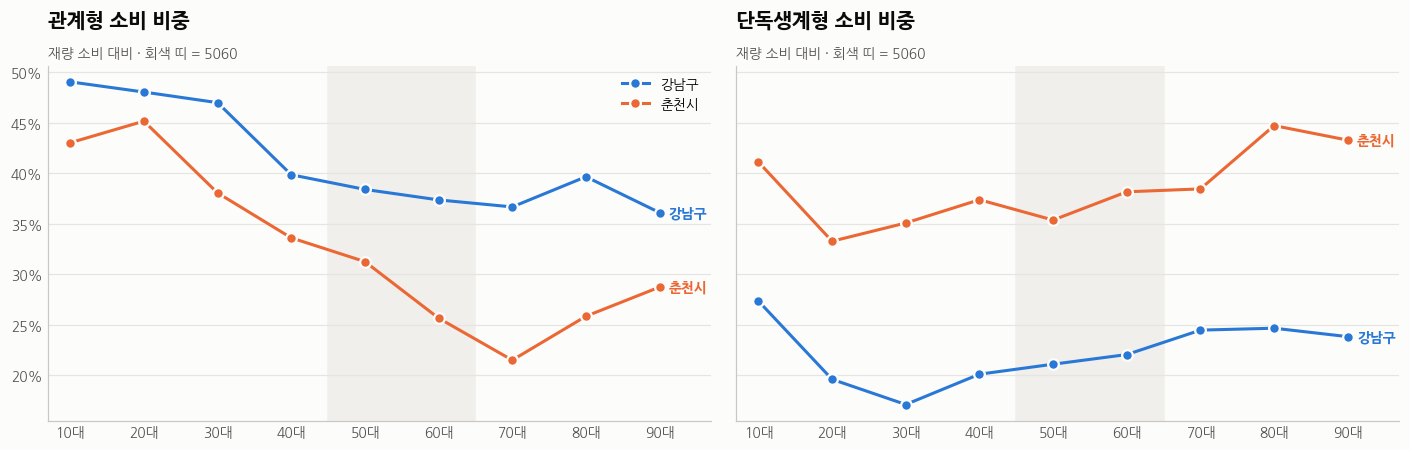

In [14]:
# 연령별 관계형·단독생계형 소비 비중 (재량 소비 대비)
s = disc.pivot_table(index=['SGG_CD', 'AGE_CCD'], columns='ISO_GRP', values='TS_AT', aggfunc='sum')
s = s.div(s.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, grp in zip(axes, ['관계형', '단독생계형']):
    ax.axvspan(3.5, 5.5, color=BAND, zorder=0)
    for cd in s.index.levels[0]:
        nm = SGG_NM[cd]; v = s.loc[cd, grp].reindex(CARD_AGE)
        ax.plot(range(len(CARD_AGE)), v.values, marker='o', color=C[nm], label=nm,
                markeredgecolor=SURF, markeredgewidth=1.5)
        ax.annotate(nm, (len(CARD_AGE) - 1, v.iloc[-1]), xytext=(6, 0), textcoords='offset points',
                    color=C[nm], fontsize=9, va='center', fontweight='bold')
    ax.set_xticks(range(len(CARD_AGE)), CARD_AGE); ax.yaxis.set_major_formatter(pct)
    ax.set_xlim(-0.3, len(CARD_AGE) - 0.3)
    ax.set_title(f'{grp} 소비 비중'); subtitle(ax, '재량 소비 대비 · 회색 띠 = 5060')
    clean(ax)
axes[0].legend(loc='upper right'); plt.tight_layout(); plt.show()

**📌 해석**
- **관계형 소비 비중은 나이가 들수록 줄어든다.** 춘천은 20대 45% → 50대 31% → 60대 26% → 70대 21%로 급감
- **단독생계형 비중은 반대로 늘어난다.** 춘천 5060은 재량 소비의 35\~38%를 편의점·슈퍼·식품에 사용
- 강남은 연령에 따른 하락 폭이 작다 (5060 약 37\~38%) → 상권 구조와 외지인 효과가 섞인 결과로 보임
- 👉 5060은 **관계형 소비가 줄고 단독 소비가 늘어나는 전환 구간** → 아래에서 5060 관계형 소비 비중을 성·연령별로 자세히 본다

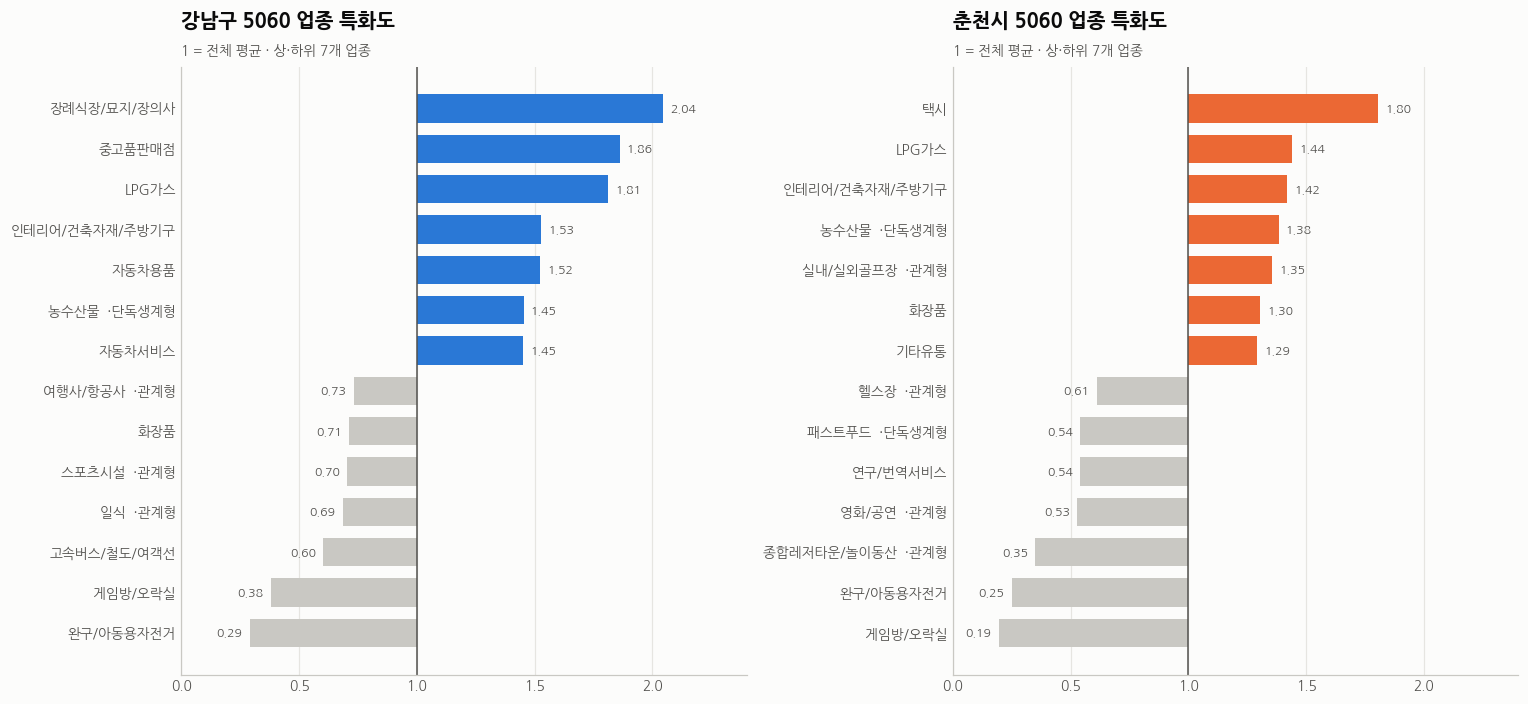

In [15]:
# 5060 업종 특화도 (LQ) = 업종 내 5060 매출 비중 / 전체 매출 중 5060 비중
#   재량 소비 업종, 매출 10억 원 이상만 / LQ > 1 이면 5060이 상대적으로 많이 쓰는 업종
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, (cd, d) in zip(axes, disc.groupby('SGG_CD')):
    nm = SGG_NM[cd]
    t = d.pivot_table(index='MCT_RY_CD', columns='AGE_GRP', values='TS_AT', aggfunc='sum', fill_value=0)
    t = t[t.sum(axis=1) >= 1e9]
    lq = ((t['5060'] / t.sum(axis=1)) / (t['5060'].sum() / t.values.sum())).sort_values()
    sel = pd.concat([lq.head(7), lq.tail(7)])
    grp = sel.index.map(ISO_MAP).fillna('일반')
    colors = [C[nm] if v >= 1 else '#c9c8c3' for v in sel]
    y = np.arange(len(sel))
    ax.barh(y, sel.values - 1, left=1, height=0.7, color=colors)
    ax.axvline(1, color=INK2, lw=1)
    ax.set_yticks(y, [f'{i}  ·{g}' if g != '일반' else i for i, g in zip(sel.index, grp)])
    for yi, v in zip(y, sel.values):
        ax.text(v + (0.03 if v >= 1 else -0.03), yi, f'{v:.2f}', va='center',
                ha='left' if v >= 1 else 'right', fontsize=8, color=INK2)
    ax.set_xlim(0, 2.4); ax.set_title(f'{nm} 5060 업종 특화도'); subtitle(ax, '1 = 전체 평균 · 상·하위 7개 업종')
    clean(ax, grid='x')
plt.tight_layout(); plt.show()

**📌 해석** (LQ > 1: 5060이 다른 연령보다 상대적으로 많이 쓰는 업종)
- **5060 특화**: 장례식장, LPG가스, 인테리어/건축자재, 농수산물, 자동차 관련, 택시 → 가족 행사·주거·차량 등 **생활 유지형** 소비
- **5060 비특화**: 게임방, 완구, 놀이동산, 영화/공연, 헬스장, 스포츠시설, 일식·양식 → **여가·문화·사교형** 소비가 적다
- 관계형 업종 중 5060 특화는 **골프장(춘천)** 정도뿐이고, 대부분의 관계형 업종(공연·운동·외식)은 1 미만
- 👉 5060의 사회적 활동이 여가·문화 영역에서 약하다는 근거

### 5060 관계형 소비 비중 (시군구 단위)
카드 데이터는 시군구 단위이므로 동으로 나누지 않고 **강남·춘천 × 성 × 연령** 수준에서만 본다 (EDA 전용, 클러스터링 미사용)

5060 전체 관계형 비중 (금액): {'강남구': '38.0%', '춘천시': '29.0%'}
5060 전체 관계형 비중 (건수): {'강남구': '36.7%', '춘천시': '32.2%'}


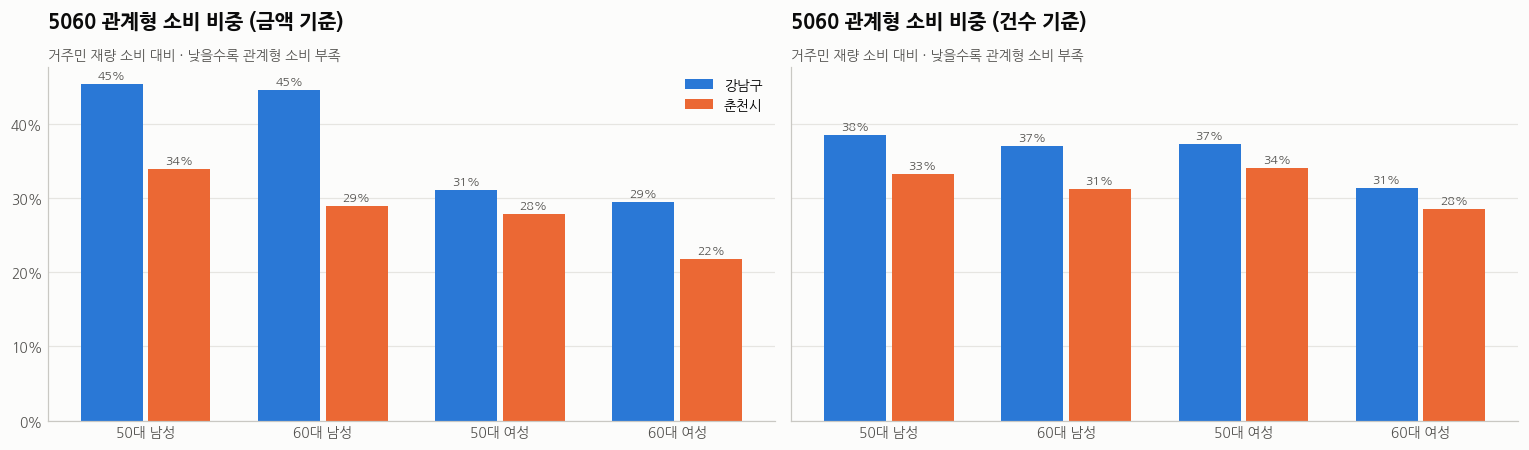

In [16]:
# 5060 관계형 소비 비중 = 관계형 ÷ 재량 소비 (거주민) - 금액 기준 vs 건수 기준
cells = ['50대 남성', '60대 남성', '50대 여성', '60대 여성']
d5060 = disc[disc.AGE_CCD.isin(T5060)].assign(CELL=lambda d: d.AGE_CCD + ' ' + d.SEX_CCD)

soc = {}
for val, nm_val in [('TS_AT', '금액'), ('USE_CNT', '건수')]:
    t = d5060.pivot_table(index=['SGG_CD', 'CELL'], columns='ISO_GRP', values=val, aggfunc='sum')
    soc[nm_val] = (t['관계형'] / t.sum(axis=1)).unstack(0).reindex(cells).rename(columns=SGG_NM)
    t_all = d5060.pivot_table(index='SGG_CD', columns='ISO_GRP', values=val, aggfunc='sum')
    print(f'5060 전체 관계형 비중 ({nm_val}):', (t_all['관계형'] / t_all.sum(axis=1)).rename(SGG_NM).map('{:.1%}'.format).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
x = np.arange(len(cells)); w = 0.38
for ax, (nm_val, v) in zip(axes, soc.items()):
    for i, nm in enumerate(REGIONS):
        bars = ax.bar(x + (i - 0.5) * w, v[nm], width=w - 0.03, color=C[nm], label=nm)
        ax.bar_label(bars, labels=[f'{u:.0%}' for u in v[nm]], padding=2, fontsize=8, color=INK2)
    ax.set_xticks(x, cells); ax.yaxis.set_major_formatter(pct)
    ax.set_title(f'5060 관계형 소비 비중 ({nm_val} 기준)'); subtitle(ax, '거주민 재량 소비 대비 · 낮을수록 관계형 소비 부족')
    clean(ax)
axes[0].legend(); plt.tight_layout(); plt.show()

**📌 해석**
- 5060 전체 관계형 소비 비중: **강남 38.0% vs 춘천 29.0%** (금액) / **36.7% vs 32.2%** (건수) → 춘천 5060의 관계형 소비가 더 약함
- 두 기준 모두에서 **60대 여성이 가장 낮다** (금액 강남 29%·춘천 22%, 건수 강남 31%·춘천 28%) → 가장 안정적인 발견
- **금액 기준에서는 남성이 크게 높지만(강남 45% vs 여성 29\~31%), 건수 기준에서는 남녀 차이가 거의 사라진다**
  - 남성이 관계형 업종에서 **한 번에 큰 금액**을 결제한다는 뜻 (모임 비용 대납, 골프장 등 고단가 업종)
  - 카드는 **결제자 기준**이므로 금액만 보면 남성의 사회 활동이 과대평가될 수 있다
- 👉 고립(만남의 빈도) 관점에서는 **건수 기준**이 더 적합
- ⚠️ 카드 데이터는 시군구 단위라 이 지표는 **동별 클러스터링에는 넣지 않고**, 지역·집단 수준 근거로만 사용한다 (군집 해석, 복지자원 추천 근거)

## 6. 유동인구 - 지역·동별 활동 리듬
- 월별 집계 3개 테이블: 연령·성별 / 요일별 / 시간대별 (47개 동 × 2025-07 \~ 12, 6개월)
- 연령 정보는 연령·성별 테이블에만 있으므로 5060 분석은 6-2에서, 요일·시간대는 지역·동 단위로 본다
- ⚠️ 연령 구간은 **10대 \~ 50대, 60세 이상(`60GU`)** 6개뿐이다. `60GU`에는 70·80대가 포함되므로 "60대"로 읽으면 안 된다

In [17]:
# 월별 유동인구 3개 (0장의 DB 경로 공통 사용)
read_flow = lambda name: (pd.read_csv(DB / f'{name}.csv', dtype={'EMD_CD': str, 'STD_YM': str}, encoding='utf-8-sig')
                            .rename(columns={'SIGUNGU_NM': 'SGG_NM'}))   # 시군구 '이름'이므로 SGG_NM으로 둔다
flow_age  = read_flow('flow_age_monthly').drop(columns='기준월')   # 행정동 × 월 × 성·연령
flow_day  = read_flow('flow_day_monthly')                          # 행정동 × 월 × 요일
flow_time = read_flow('flow_time_monthly')                         # 행정동 × 월 × 시간대
flows = {'flow_age_monthly': flow_age, 'flow_day_monthly': flow_day, 'flow_time_monthly': flow_time}

FLOW_AGE     = {'10G': '10대', '20G': '20대', '30G': '30대', '40G': '40대', '50G': '50대', '60GU': '60세 이상'}
AGE_COLS     = [c for c in flow_age.columns if c.startswith(('MAN_', 'WMAN_'))]
FLOW_5060    = ['MAN_FLOW_POP_CNT_50G', 'MAN_FLOW_POP_CNT_60GU', 'WMAN_FLOW_POP_CNT_50G', 'WMAN_FLOW_POP_CNT_60GU']
WEEKDAY_COLS = ['FLOW_POP_CNT_MON', 'FLOW_POP_CNT_TUS', 'FLOW_POP_CNT_WED', 'FLOW_POP_CNT_THU', 'FLOW_POP_CNT_FRI']
WEEKEND_COLS = ['FLOW_POP_CNT_SAT', 'FLOW_POP_CNT_SUN']
HOUR_COLS    = [f'TMST_{h:02d}' for h in range(24)]

pd.DataFrame({name: {'rows': len(df), 'cols': df.shape[1], '동 수': df.EMD_CD.nunique(), '월 수': df.STD_YM.nunique(),
                     '결측치': int(df.isna().sum().sum()),
                     '동·월 중복': int(df.duplicated(['EMD_CD', 'STD_YM']).sum()),
                     '동 목록 = EMD_MST': set(df.EMD_CD) == set(emd_mst.EMD_CD)}
              for name, df in flows.items()}).T

,rows,cols,동 수,월 수,결측치,동·월 중복,동 목록 = EMD_MST
flow_age_monthly,282,16,47,6,0,0,True
flow_day_monthly,282,11,47,6,0,0,True
flow_time_monthly,282,28,47,6,0,0,True


**📌 해석**
- 3개 테이블 모두 **47개 동 × 6개월 = 282행**, 결측치·중복 없음, 동 목록이 `EMD_MST`와 일치 → `EMD_CD`로 바로 결합 가능
- 지역 컬럼(`SIGUNGU_NM`)은 코드가 아닌 **시군구 이름**이라 `SGG_NM`으로 바꿔 읽었다 (DB 테이블의 `SGG_CD`와 혼동 방지)

### 6-1. 월별 변화

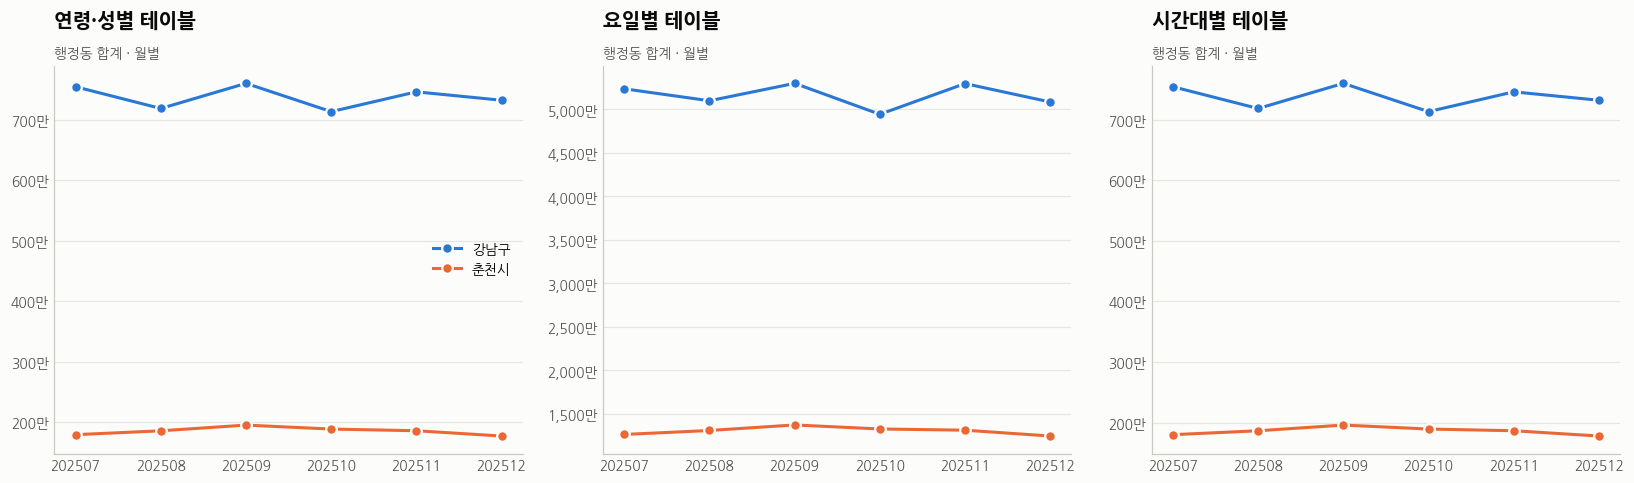

연령·성별               요일별              시간대별        
           min     max       min       max     min     max
SGG_NM                                                    
강남구    713.000 760.000 4,940.000 5,296.000 713.000 760.000
춘천시    177.000 195.000 1,242.000 1,369.000 178.000 196.000

In [18]:
# 테이블별 지역 월합계 (세 테이블의 총량이 같은지도 함께 확인)
trend = pd.DataFrame({
    '연령·성별': flow_age.groupby(['SGG_NM', 'STD_YM'])[AGE_COLS].sum().sum(axis=1),
    '요일별':    flow_day.groupby(['SGG_NM', 'STD_YM'])[WEEKDAY_COLS + WEEKEND_COLS].sum().sum(axis=1),
    '시간대별':  flow_time.groupby(['SGG_NM', 'STD_YM'])[HOUR_COLS].sum().sum(axis=1),
})

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, trend.columns):
    for nm in REGIONS:
        g = trend.loc[nm, col]
        ax.plot(g.index, g.values, marker='o', color=C[nm], label=nm, markeredgecolor=SURF, markeredgewidth=1.5)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v / 1e4:,.0f}만'))
    ax.set_title(f'{col} 테이블'); subtitle(ax, '행정동 합계 · 월별')
    clean(ax)
axes[0].legend(); plt.tight_layout(); plt.show()

(trend.groupby('SGG_NM').agg(['min', 'max']) / 1e4).round(0)

**📌 해석**
- 연령·성별과 시간대별 테이블은 월합계가 같고(강남 713\~760만, 춘천 177\~196만), 요일별은 약 **7배**다 → 요일별 값은 요일마다의 일평균이라 7개 요일을 더하면 7배가 된다. **테이블 간 절대값은 비교하지 않는다**
- 세 테이블 모두에서 강남구가 춘천시보다 약 **4배** 많다
- 강남구: 9월이 가장 많고 8월·10월에 줄어든다 → 휴가철·추석 연휴(10/3\~10/9)에 업무 중심지 유동이 빠짐
- 춘천시: 9월이 가장 많고 이후 12월까지 감소 → 가을 나들이 정점 후 기온 하락에 따른 야외 활동 감소
- 👉 고립 위험군의 외부 접촉은 **강남은 연휴, 춘천은 겨울**에 더 줄어들 수 있다

### 6-2. 성·연령 구성과 5060 유동인구

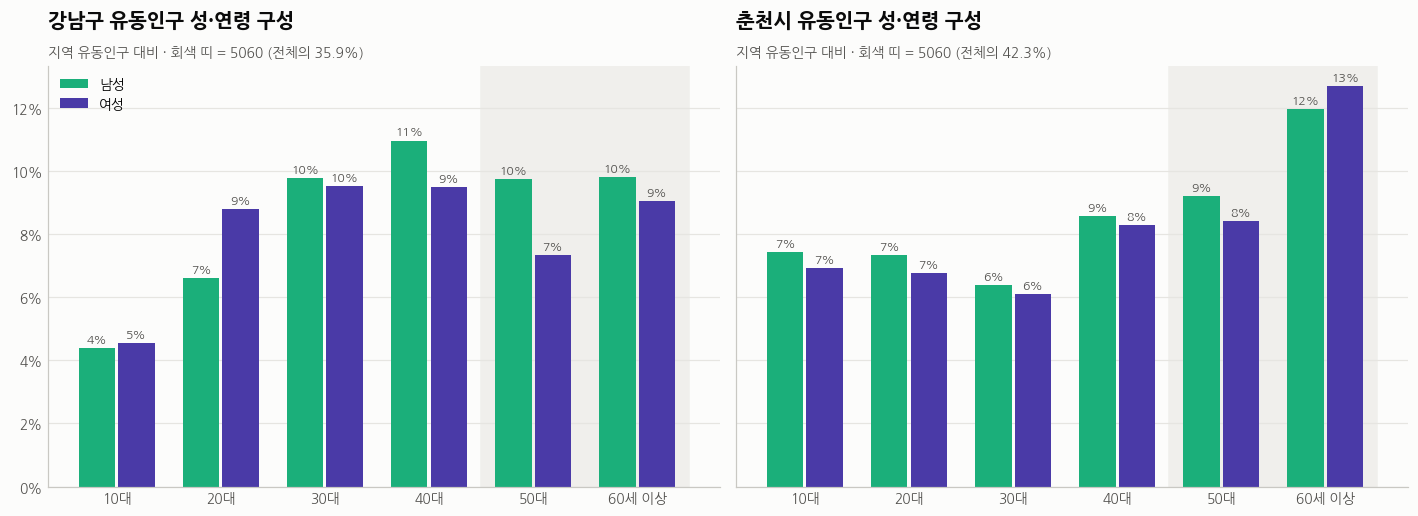

In [19]:
age_long = (flow_age.groupby('SGG_NM')[AGE_COLS].sum().stack().rename('유동인구')
                    .rename_axis(['SGG_NM', 'COL']).reset_index())
age_long['성별']  = np.where(age_long.COL.str.startswith('WMAN_'), '여성', '남성')
age_long['연령대'] = age_long.COL.str.split('_').str[-1].map(FLOW_AGE)
FLOW_AGE_ORDER = list(FLOW_AGE.values())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
x = np.arange(len(FLOW_AGE_ORDER)); w = 0.38
for ax, nm in zip(axes, REGIONS):
    t = (age_long[age_long.SGG_NM == nm]
         .pivot_table(index='연령대', columns='성별', values='유동인구', aggfunc='sum').reindex(FLOW_AGE_ORDER))
    t = t / t.values.sum()
    ax.axvspan(3.5, 5.5, color=BAND, zorder=0)
    for i, sex in enumerate(['남성', '여성']):
        bars = ax.bar(x + (i - 0.5) * w, t[sex], width=w - 0.03, color=C[sex], label=sex)
        ax.bar_label(bars, labels=[f'{v:.0%}' for v in t[sex]], padding=2, fontsize=8, color=INK2)
    ax.set_xticks(x, FLOW_AGE_ORDER); ax.yaxis.set_major_formatter(pct)
    ax.set_title(f'{nm} 유동인구 성·연령 구성')
    subtitle(ax, f'지역 유동인구 대비 · 회색 띠 = 5060 (전체의 {t.loc[["50대", "60세 이상"]].values.sum():.1%})')
    clean(ax)
axes[0].legend(loc='upper left'); plt.tight_layout(); plt.show()

**📌 해석**
- **춘천**은 남녀 모두 `60세 이상`이 가장 크다 (남 12%, 여 13%). 단, 이 구간은 60\~80대 이상을 합친 30년 이상 폭이라 10년 폭인 다른 구간보다 커지는 것이 당연하다 → "60대가 가장 많다"는 결론은 낼 수 없다
- **강남**은 40대 남성(11%)이 가장 크고, 50대 이상에서는 **남성 > 여성** 격차가 뚜렷하다 (50대 남 10% vs 여 7%) → 업무·상권 유동 중심
- 50대 + 60세 이상 비중: **강남 35.9%, 춘천 42.3%**. 70대 이상이 섞여 있어 **실제 5060보다 과대 추정**된 값이다
- 👉 유동인구의 5060 지표는 "50세 이상 유동인구"로 이름 붙여 해석한다

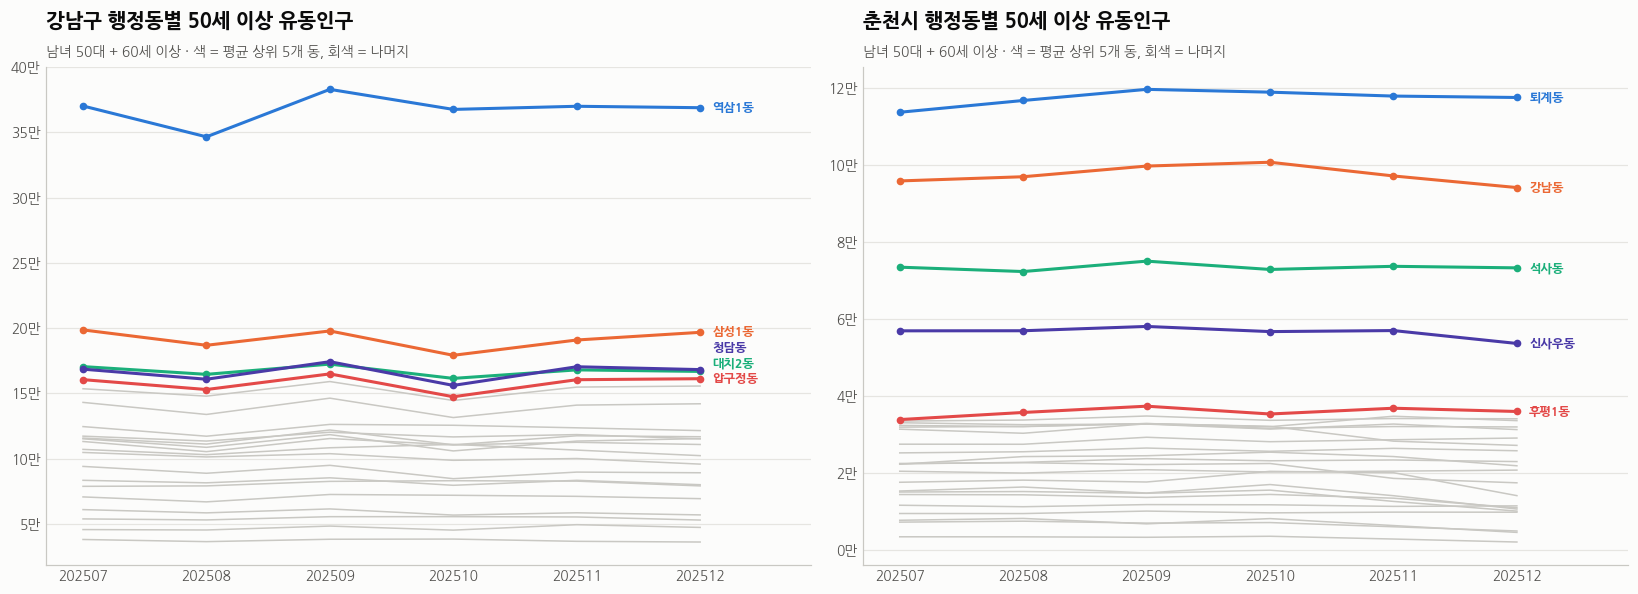

50세 이상 유동인구 7월→12월 변화율 (지역별 중앙값): {'강남구': '-1.7%', '춘천시': '-1.8%'}


In [20]:
# 행정동별 50세 이상 유동인구 월별 추이 (지역별 상위 5개 동만 색으로 강조)
flow_age['FLOW_50P'] = flow_age[FLOW_5060].sum(axis=1)
d50 = flow_age.pivot_table(index='STD_YM', columns=['SGG_NM', 'EMD_NM'], values='FLOW_50P', aggfunc='sum')

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, nm in zip(axes, REGIONS):
    t = d50[nm]
    top = t.mean().nlargest(5).index
    for dong in t.columns.difference(top):
        ax.plot(t.index, t[dong], color='#c9c8c3', lw=1, zorder=2)
    for dong, col in zip(top, ['#2a78d6', '#eb6834', '#1baf7a', '#4a3aa7', '#e34948']):
        ax.plot(t.index, t[dong], marker='o', markersize=4, color=col, lw=2, zorder=3)
    # 끝점 라벨: 가까운 라벨끼리 겹치지 않도록 세로 간격 확보
    ends = t[top].iloc[-1].sort_values(); gap = (t.values.max() - t.values.min()) * 0.035; ys = []
    for v in ends.values:
        ys.append(max(v, ys[-1] + gap) if ys else v)
    for (dong, v), y in zip(ends.items(), ys):
        col = ['#2a78d6', '#eb6834', '#1baf7a', '#4a3aa7', '#e34948'][list(top).index(dong)]
        ax.annotate(dong, (len(t) - 1, v), xytext=(len(t) - 0.9, y), textcoords='data',
                    color=col, fontsize=8, va='center', fontweight='bold')
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v / 1e4:,.0f}만'))
    ax.set_xlim(-0.3, len(t) - 0.1)
    ax.set_title(f'{nm} 행정동별 50세 이상 유동인구'); subtitle(ax, '남녀 50대 + 60세 이상 · 색 = 평균 상위 5개 동, 회색 = 나머지')
    clean(ax)
plt.tight_layout(); plt.show()

chg = (d50.iloc[-1] / d50.iloc[0] - 1).rename('7월→12월 변화율')
print('50세 이상 유동인구 7월→12월 변화율 (지역별 중앙값):', chg.groupby(level=0).median().map('{:+.1%}'.format).to_dict())

**📌 해석**
- 동별 50세 이상 유동인구는 월별 순위가 거의 바뀌지 않는다 → 동 간 차이가 월 변동보다 훨씬 크다
- 강남은 역삼1동(월 35\~38만)이 2위 삼성1동의 약 2배로 압도적, 춘천은 퇴계동·강남동·석사동 등 **주거 밀집 동**이 상위
- 7월→12월 변화율 중앙값은 강남 −1.7%, 춘천 −1.8%로 작다
- 👉 동별 지표로 쓸 때는 6개월 평균 하나로 요약해도 정보 손실이 작다

### 6-3. 평일·주말 활동 패턴

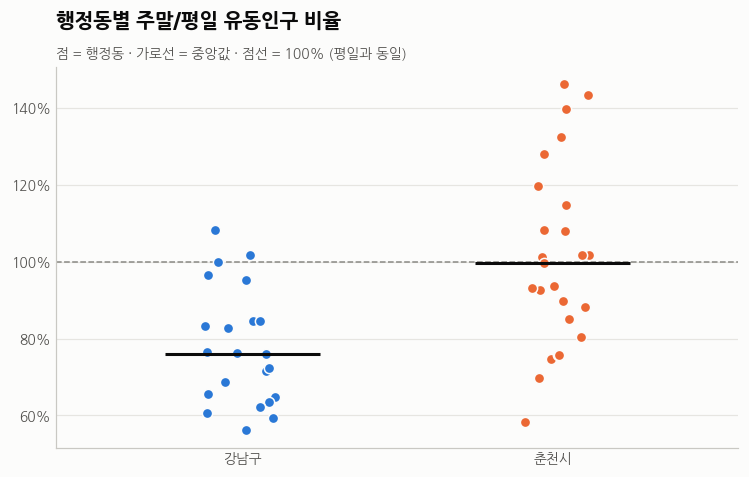

In [21]:
day = flow_day.assign(평일_일평균=flow_day[WEEKDAY_COLS].mean(axis=1),
                      주말_일평균=flow_day[WEEKEND_COLS].mean(axis=1))
dong_activity = (day.groupby(['SGG_NM', 'EMD_CD', 'EMD_NM'], as_index=False)[['평일_일평균', '주말_일평균']].mean()
                    .assign(**{'주말/평일_비율': lambda d: d.주말_일평균 / d.평일_일평균}))

fig, ax = plt.subplots(figsize=(8, 4.5))
rng = np.random.default_rng(0)
for i, nm in enumerate(REGIONS):
    v = dong_activity.loc[dong_activity.SGG_NM == nm, '주말/평일_비율']
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(v)), v, s=45, color=C[nm], edgecolor=SURF, linewidth=1, zorder=3)
    ax.hlines(v.median(), i - 0.25, i + 0.25, color=INK, lw=2, zorder=4)
ax.axhline(1, color=MUTED, ls='--', lw=1)
ax.set_xticks(range(len(REGIONS)), REGIONS); ax.set_xlim(-0.6, 1.6)
ax.yaxis.set_major_formatter(pct)
ax.set_title('행정동별 주말/평일 유동인구 비율'); subtitle(ax, '점 = 행정동 · 가로선 = 중앙값 · 점선 = 100% (평일과 동일)')
clean(ax); plt.show()

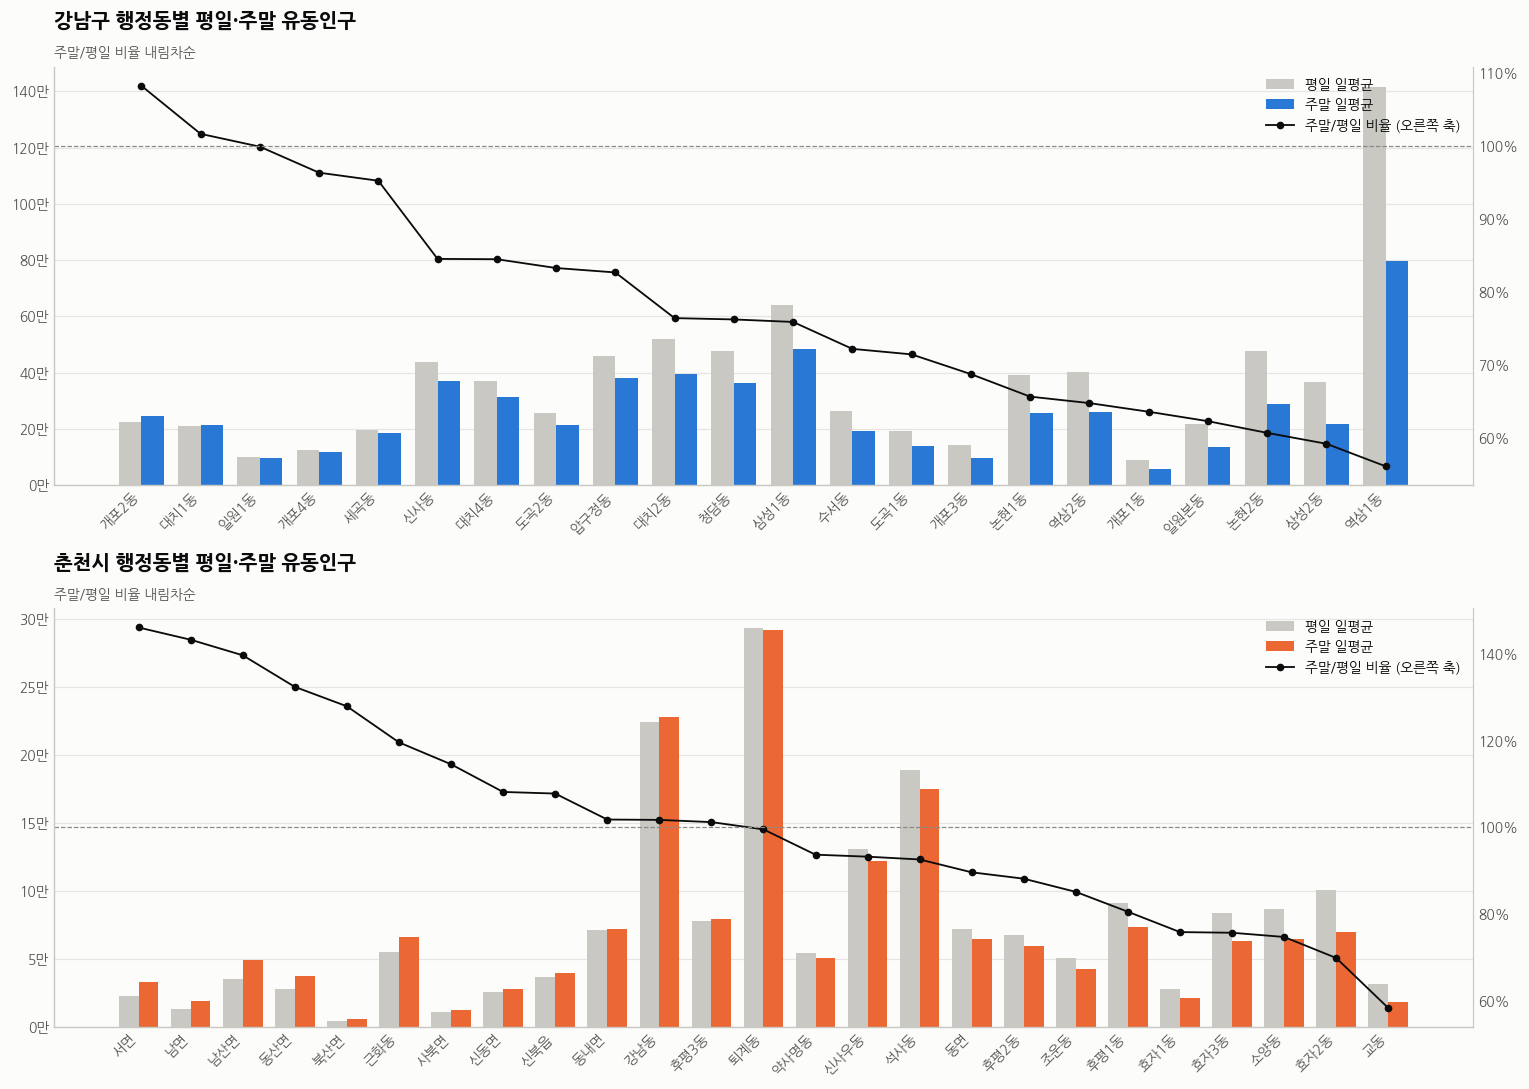

[강남구] 상위 3: 개포2동(108%), 대치1동(102%), 일원1동(100%) | 하위 3: 논현2동(61%), 삼성2동(59%), 역삼1동(56%)
[춘천시] 상위 3: 서면(146%), 남면(143%), 남산면(140%) | 하위 3: 소양동(75%), 효자2동(70%), 교동(58%)


In [22]:
# 행정동별 평일 vs 주말 일평균 (주말/평일 비율 내림차순)
fig, axes = plt.subplots(2, 1, figsize=(14, 10))
for ax, nm in zip(axes, REGIONS):
    df = dong_activity[dong_activity.SGG_NM == nm].sort_values('주말/평일_비율', ascending=False)
    x = np.arange(len(df)); w = 0.38
    ax.bar(x - w / 2, df.평일_일평균, width=w, color='#c9c8c3', label='평일 일평균')
    ax.bar(x + w / 2, df.주말_일평균, width=w, color=C[nm], label='주말 일평균')
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v / 1e4:,.0f}만'))
    ax.set_xticks(x, df.EMD_NM, rotation=45, ha='right')
    ax2 = ax.twinx()
    ax2.plot(x, df['주말/평일_비율'], color=INK, marker='o', markersize=4, lw=1.2, label='주말/평일 비율 (오른쪽 축)')
    ax2.axhline(1, color=MUTED, ls='--', lw=0.8)
    ax2.yaxis.set_major_formatter(pct); ax2.grid(False); ax2.spines['right'].set_visible(True); ax2.tick_params(length=0)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc='upper right')
    ax.set_title(f'{nm} 행정동별 평일·주말 유동인구'); subtitle(ax, '주말/평일 비율 내림차순')
    clean(ax)
plt.tight_layout(); plt.show()

for nm in REGIONS:
    df = dong_activity[dong_activity.SGG_NM == nm].sort_values('주말/평일_비율', ascending=False)
    fmt = lambda d: ', '.join(f'{n}({v:.0%})' for n, v in zip(d.EMD_NM, d['주말/평일_비율']))
    print(f'[{nm}] 상위 3: {fmt(df.head(3))} | 하위 3: {fmt(df.tail(3))}')

**📌 해석**
- **강남구**: 대부분의 동이 평일 > 주말
  - 주말 공동화: 역삼1동·삼성2동·논현2동 (주말이 평일의 56\~61%) → 오피스·직장인 상권
  - 주말 유지: 개포2동·대치1동·일원1동 (100% 이상) → 아파트 단지·학원가·근린공원 등 주거 중심지
- **춘천시**: 동 간 편차가 강남보다 훨씬 크다
  - 주말 증가: 서면·남면·남산면 (평일의 1.4배 이상) → 외곽 관광·레저지로 외지 방문객 유입
  - 주말 공동화: 교동·효자2동·소양동 (59\~75%) → 대학가·도심
- **5060 고립 관점 시사점**
  - 춘천 외곽 면 지역은 주말 유동인구가 늘어도 대부분 외부 방문객일 가능성이 높다 → 거주 중장년의 관계 단절이 가려질 수 있으므로 **상주인구 대비 지표·거주민 소비**와 함께 봐야 한다
  - 주말에 유동이 절반 수준으로 줄어드는 동(역삼1동·논현2동·교동·효자2동)은 주말 동안 이웃·상권의 비공식 돌봄이 약해질 수 있다 → 주말형 커뮤니티 프로그램 후보

### 6-4. 시간대별 생활 리듬

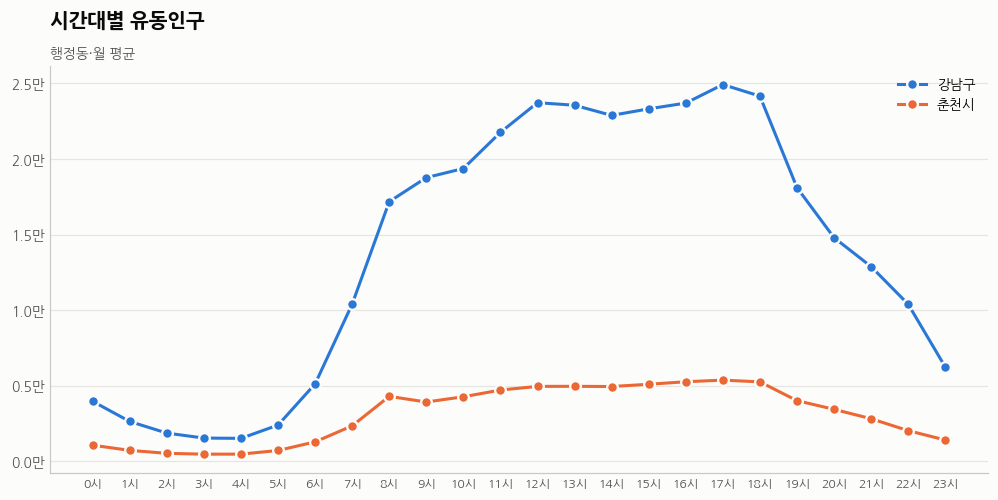

피크 시간대: {'강남구': '17시', '춘천시': '17시'}


In [23]:
# 지역별 시간대 패턴 (행정동·월 평균)
time_region = flow_time.groupby('SGG_NM')[HOUR_COLS].mean()

fig, ax = plt.subplots(figsize=(11, 4.8))
for nm in REGIONS:
    ax.plot(range(24), time_region.loc[nm].values, marker='o', color=C[nm], label=nm,
            markeredgecolor=SURF, markeredgewidth=1.5)
ax.set_xticks(range(24), [f'{h}시' for h in range(24)], fontsize=8)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v / 1e4:,.1f}만'))
ax.set_title('시간대별 유동인구'); subtitle(ax, '행정동·월 평균')
ax.legend(); clean(ax); plt.show()

print('피크 시간대:', {nm: f'{time_region.loc[nm].idxmax()[-2:]}시' for nm in REGIONS})

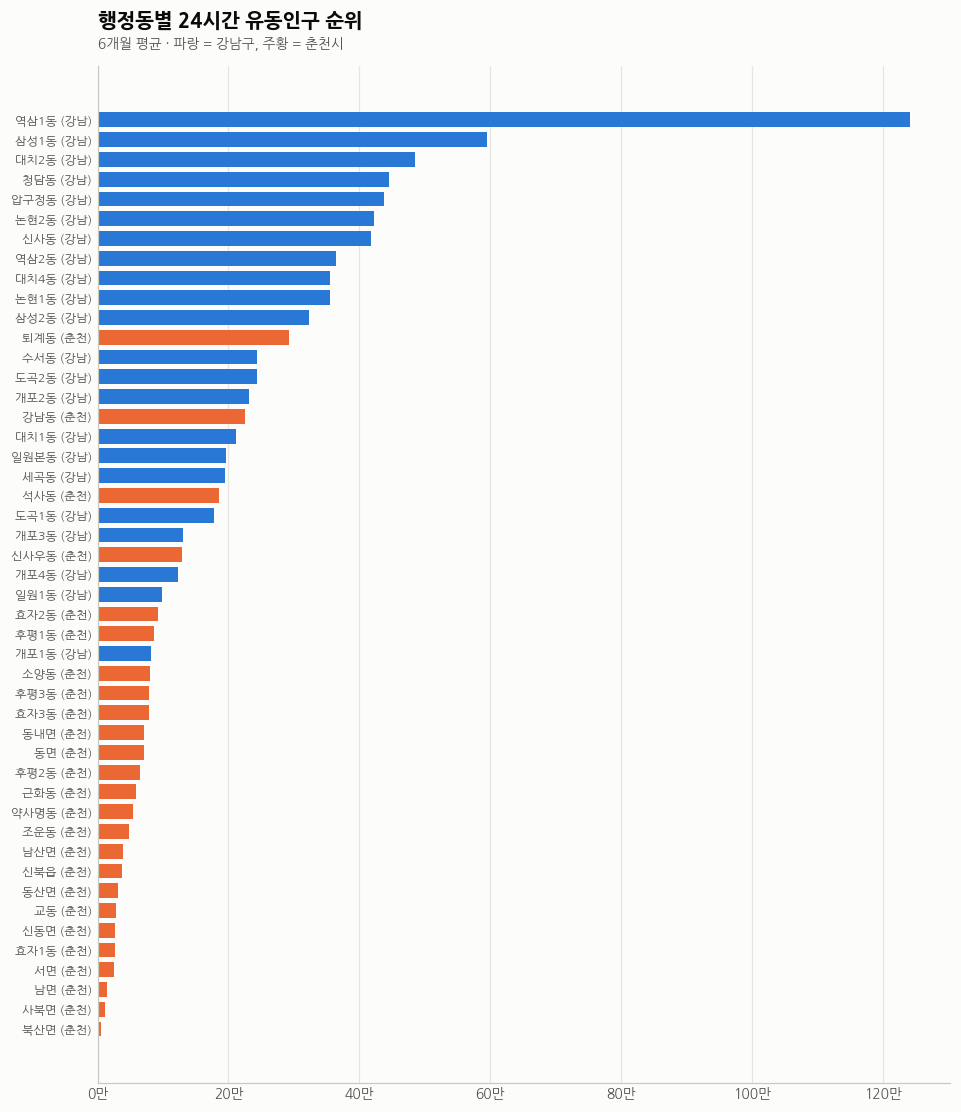

,순위,SGG_NM,EMD_NM,24시간_합계
0,1,강남구,역삼1동,"1,240,743.492"
1,2,강남구,삼성1동,"595,112.840"
2,3,강남구,대치2동,"484,770.728"
3,4,강남구,청담동,"444,680.082"
4,5,강남구,압구정동,"437,696.808"
5,6,강남구,논현2동,"423,091.028"
6,7,강남구,신사동,"417,950.240"
7,8,강남구,역삼2동,"363,568.022"
8,9,강남구,대치4동,"355,392.110"
9,10,강남구,논현1동,"354,960.123"


In [24]:
# 행정동별 6개월 평균 시간대 프로필 & 24시간 합계 순위
time_dong = flow_time.groupby(['SGG_NM', 'EMD_CD', 'EMD_NM'], as_index=False)[HOUR_COLS].mean()
time_dong['24시간_합계'] = time_dong[HOUR_COLS].sum(axis=1)
time_dong = time_dong.sort_values('24시간_합계', ascending=False).reset_index(drop=True)
time_dong['순위'] = time_dong.index + 1

fig, ax = plt.subplots(figsize=(10, 12))
p = time_dong.iloc[::-1]
ax.barh(p.EMD_NM + ' (' + p.SGG_NM.str[:2] + ')', p['24시간_합계'], color=p.SGG_NM.map(C), height=0.75)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v / 1e4:,.0f}만'))
ax.tick_params(axis='y', labelsize=8)
ax.set_title('행정동별 24시간 유동인구 순위'); subtitle(ax, '6개월 평균 · 파랑 = 강남구, 주황 = 춘천시')
clean(ax, grid='x'); plt.show()

time_dong[['순위', 'SGG_NM', 'EMD_NM', '24시간_합계']].head(10)

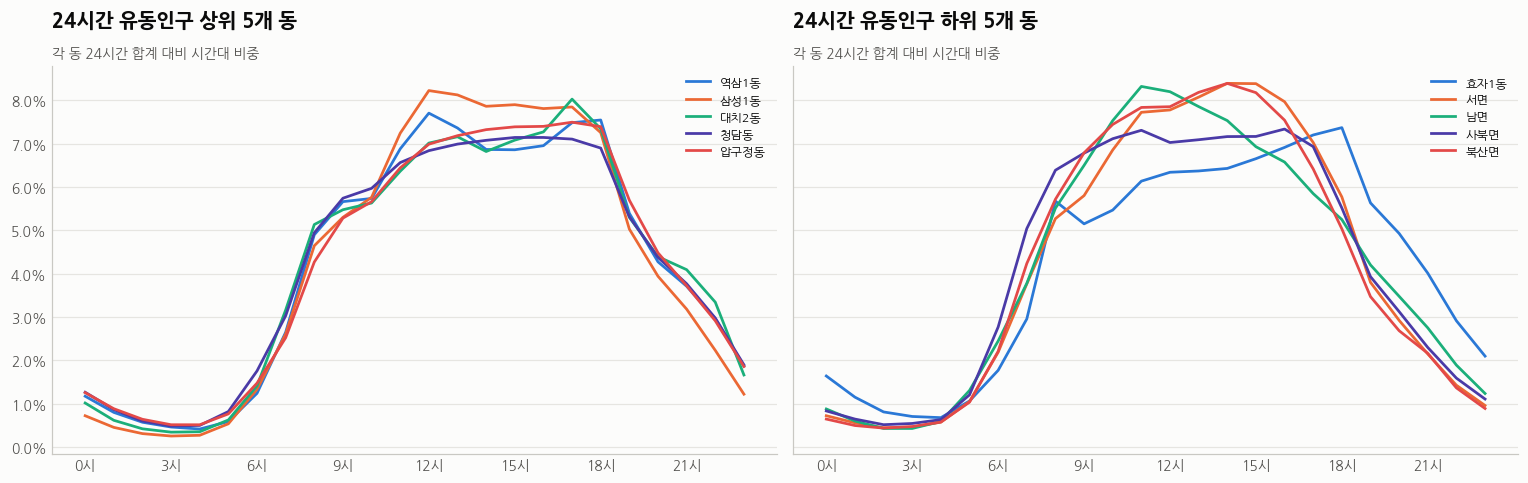

In [25]:
# 24시간 합계 상위·하위 5개 동의 시간대 패턴 - 규모 차이가 커서 각 동 합계 대비 비중으로 비교
sel = pd.concat([time_dong.head(5), time_dong.tail(5)])
share = sel.set_index('EMD_NM')[HOUR_COLS].div(sel.set_index('EMD_NM')['24시간_합계'], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (part, title) in zip(axes, [(share.iloc[:5], '상위 5개 동'), (share.iloc[5:], '하위 5개 동')]):
    for (dong, row), col in zip(part.iterrows(), ['#2a78d6', '#eb6834', '#1baf7a', '#4a3aa7', '#e34948']):
        ax.plot(range(24), row.values, color=col, lw=1.8, label=dong)
    ax.set_xticks(range(0, 24, 3), [f'{h}시' for h in range(0, 24, 3)])
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.1%}'))
    ax.set_title(f'24시간 유동인구 {title}'); subtitle(ax, '각 동 24시간 합계 대비 시간대 비중')
    ax.legend(fontsize=8); clean(ax)
plt.tight_layout(); plt.show()

**📌 해석**
- 두 지역 모두 유동인구 피크는 **17시**
- 유동인구 규모 1\~10위는 모두 강남 (역삼1동이 2위 삼성1동의 약 2배). 하위 5개 동은 모두 춘천 (북산면·사북면·남면·서면 + 효자1동)
- 규모 차이가 수십 배라 원값으로는 하위 동의 패턴이 보이지 않는다 → **동별 합계 대비 비중**으로 바꿔 비교
  - 상위 동(강남): 8시부터 늘어 12\~18시에 고르게 높은 **업무지구형**
  - 하위 면 지역: 6\~9시에 더 일찍 늘어 11\~15시에 정점, 18시 이후 빠르게 감소하는 **이른 낮 활동형** (농촌 생활 리듬)
  - 효자1동: 18시에 정점이고 야간 비중이 높은 **저녁·야간형** (대학가 인근)
- 👉 유동인구 규모는 상주인구보다 **업무·상권 기능**을 크게 반영한다. 고립 지표로 쓸 때는 원값이 아닌 비율(주말/평일, 야간 비중 등)이나 상주인구 대비 값으로 만들어야 한다

## 7. 핵심 파생변수 생성 (클러스터링 입력)
`modeling/Clustering.ipynb`와 **같은 정의**의 5개 변수 (인구축 3 + 지역축 2)
- 유동인구는 6장의 월별 테이블을 6개월 합산해 사용 (원본 `FLOW_POP_*`를 동별로 합산한 값과 동일)

In [26]:
feat = emd[['SGG_CD', 'SGG_NM', 'EMD_NM', 'TOT_POP_CNT', 'POP_DENSITY', 'RATIO_5060', 'HH1_RATIO']].copy()
PA = pop_sex_age.pivot_table(index='EMD_CD', columns='AGE_CCD', values='POP_CNT', aggfunc='sum')
feat['POP_5060'] = p5060

# ---------- 인구축 ----------
# 1-1 중장년 1인 가구 노출도: 1인 가구 비율 × 5060 인구 비중 (동별 연령별 1인 가구 통계가 없어 두 비율의 곱으로 근사)
feat['HH1_EXPO_5060'] = feat.HH1_RATIO * feat.RATIO_5060

# 1-2 5060 남성 비율: 5060 인구 중 남성
feat['MALE_SHARE_5060'] = P['남성'][T5060].sum(axis=1) / p5060

# 1-3 중장년 생활 노출 지수: (유동인구 중 5060 비중) ÷ (주민 중 5060 비중)
FA    = flow_age.groupby('EMD_CD')[AGE_COLS].sum()
f50   = FA.MAN_FLOW_POP_CNT_50G + FA.WMAN_FLOW_POP_CNT_50G
f60gu = FA.MAN_FLOW_POP_CNT_60GU + FA.WMAN_FLOW_POP_CNT_60GU
r60   = PA['60대'] / PA[AGE_ORDER[6:]].sum(axis=1)                  # 주민 60세 이상 중 60대 비율
flow5060 = f50 + f60gu * r60                                          # 60GU(60세 이상) 중 60대만 추정
resident_10p = PA.drop(columns='10대미만').sum(axis=1)                # 유동인구에 10세 미만이 없으므로 분모 맞춤
feat['VISIBLE_IDX_50P'] = (flow5060 / FA.sum(axis=1)) / (p5060 / resident_10p)

# ---------- 지역축 ----------
# 2-1 생활 리듬 다양성: 시간대별 유동 비중 p_h → 엔트로피 -Σ p_h log p_h (최댓값 log 24 ≈ 3.178)
T = flow_time.groupby('EMD_CD')[HOUR_COLS].sum()
p_h = T.div(T.sum(axis=1), axis=0)
feat['TIME_ENTROPY'] = -(p_h * np.log(p_h)).sum(axis=1)

# 2-2 물리적 밀집도: 총인구 ÷ 면적 → 2장에서 만든 POP_DENSITY

POP_AX  = ['HH1_EXPO_5060', 'MALE_SHARE_5060', 'VISIBLE_IDX_50P']
REG_AX  = ['TIME_ENTROPY', 'POP_DENSITY']
VARS    = POP_AX + REG_AX
RISK_UP = {'HH1_EXPO_5060': True, 'MALE_SHARE_5060': True, 'VISIBLE_IDX_50P': False,
           'TIME_ENTROPY': False, 'POP_DENSITY': False}             # True = 높을수록 위험
SHORT   = {'HH1_EXPO_5060': '1-1 1인 노출', 'MALE_SHARE_5060': '1-2 남성 비율', 'VISIBLE_IDX_50P': '1-3 생활 노출',
           'TIME_ENTROPY': '2-1 생활 리듬', 'POP_DENSITY': '2-2 인구밀도'}
KEY = ['HH1_EXPO_5060', 'MALE_SHARE_5060']                           # 8-4 인구축 두 변수 분석용

print('결측:', int(feat[VARS].isna().sum().sum()), '| 무한대:', int(np.isinf(feat[VARS]).sum().sum()), '| 동 수:', len(feat))
feat[['SGG_NM', 'EMD_NM'] + VARS].head()

결측: 0 | 무한대: 0 | 동 수: 47


,SGG_NM,EMD_NM,HH1_EXPO_5060,MALE_SHARE_5060,VISIBLE_IDX_50P,TIME_ENTROPY,POP_DENSITY
EMD_CD,,,,,,,
11230510,강남구,신사동,0.109,0.475,0.827,2.954,"7,979.365"
11230520,강남구,논현1동,0.166,0.485,0.962,2.965,"16,517.600"
11230530,강남구,논현2동,0.151,0.478,0.885,2.934,"13,679.592"
11230770,강남구,압구정동,0.079,0.473,0.806,2.944,"10,056.917"
11230780,강남구,청담동,0.113,0.472,0.899,2.956,"10,822.747"


**인구축 - 그 동에 고립되기 쉬운 중장년이 얼마나 있는가**
- **1-1 `HH1_EXPO_5060` (중장년 1인 가구 노출도)**: 1인 가구 비율 × 5060 인구 비중 → 두 조건이 **동시에** 높은 동일수록 값이 큼
  - 근거: 동별 연령별 1인 가구 통계가 없어 두 비율의 곱으로 근사. 1인 가구 비율만 쓰면 청년 밀집지가 위험으로 잡힘 (3장)
  - ⚠️ 강남은 동별 5060 비중 차이가 작아(22\~34%) 역삼1동·논현1동 같은 청년 1인 가구 밀집지가 여전히 상위에 남음
- **1-2 `MALE_SHARE_5060` (5060 남성 비율)**: 동의 5060 인구 중 남성 비율
  - 근거: 고독사는 남성이 여성보다 약 4배 많고, 중장년 남성은 사회적 관계망이 가장 약한 집단 (참고 논문: 김소연 외, 2024)
- **1-3 `VISIBLE_IDX_50P` (중장년 생활 노출 지수)**: (유동인구 중 5060 비중) ÷ (주민 중 5060 비중)
  - 1보다 작으면 주민 구성에 비해 거리에서 5060이 **덜 보인다** → 집 밖 활동이 적은 동 (낮을수록 위험)
  - 유동인구 연령이 `60세 이상(60GU)`으로 묶여 있어(6장), 주민의 60세 이상 중 60대 비율을 곱해 **60대만 추정**. 분모도 유동인구처럼 10세 이상 주민 기준

**지역축 - 그 동이 사람을 만나기 어려운 환경인가**
- **2-1 `TIME_ENTROPY` (생활 리듬 다양성)**: 하루 유동인구가 24개 시간대에 고르게 퍼질수록 큼 (최댓값 3.178)
  - 낮을수록 특정 시간대에만 사람이 몰리고 **나머지 시간은 비어 있다** (6-4의 업무지구형·이른 낮 활동형)
- **2-2 `POP_DENSITY` (물리적 밀집도)**: 낮을수록 이웃과 마주칠 기회가 적다

⚠️ 다섯 변수 모두 **비율·밀도**라 동의 인구 규모는 반영하지 않는다. 북산면(총인구 935명)처럼 인구가 적은 동은 값이 크게 흔들릴 수 있다

## 8. 파생변수 EDA & 프로파일링

### 8-1. 시군구별 분포

In [27]:
feat.groupby('SGG_NM')[VARS].agg(['min', 'median', 'max', 'std']).T

SGG_NM                        강남구        춘천시
HH1_EXPO_5060   min         0.020      0.093
                median      0.105      0.175
                max         0.176      0.308
                std         0.045      0.061
MALE_SHARE_5060 min         0.452      0.458
                median      0.479      0.507
                max         0.528      0.598
                std         0.020      0.039
VISIBLE_IDX_50P min         0.760      0.693
                median      0.975      0.873
                max         1.099      1.004
                std         0.097      0.085
TIME_ENTROPY    min         2.866      2.877
                median      2.956      2.960
                max         2.998      3.014
                std         0.030      0.043
POP_DENSITY     min     6,540.722      4.350
                median 15,358.309  2,169.304
                max    31,458.824 18,535.616
                std     7,775.512  5,639.461

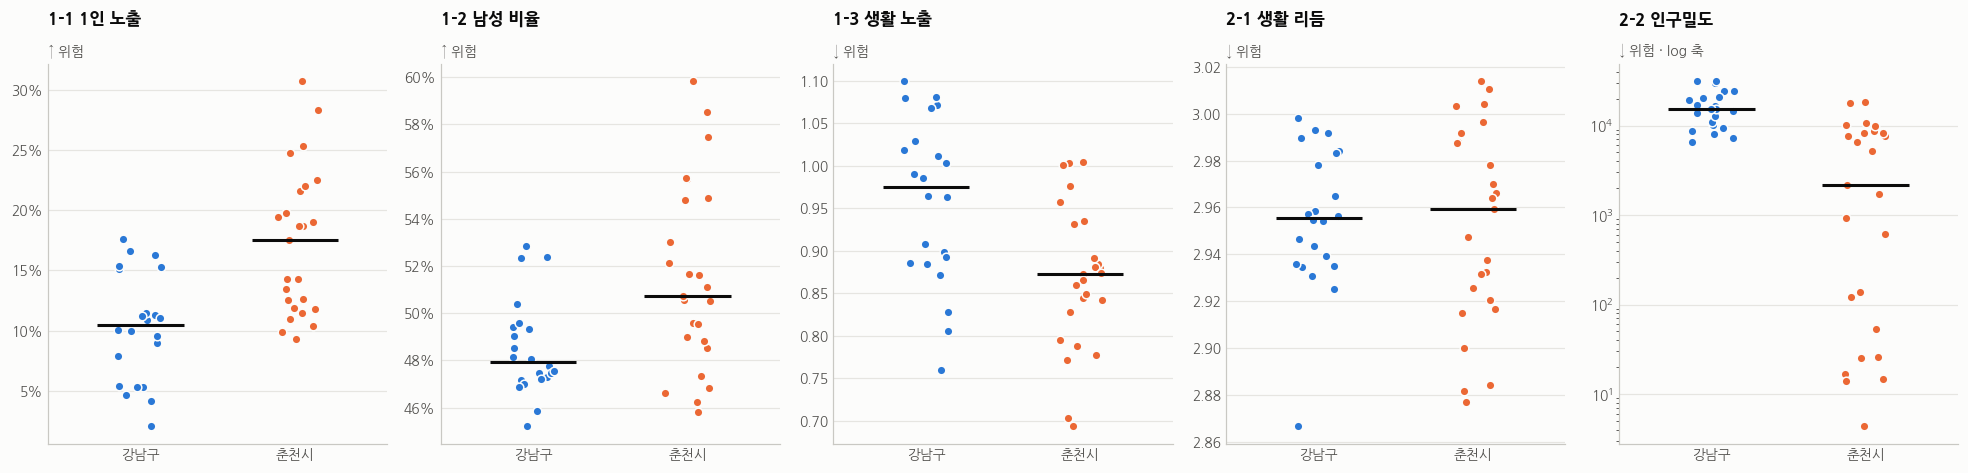

In [28]:
# 시군구별 분포 (점 = 행정동, 가로선 = 중앙값)
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 5, figsize=(18, 4.4))
for ax, k in zip(axes, VARS):
    for i, nm in enumerate(REGIONS):
        v = feat.loc[feat.SGG_NM == nm, k]
        ax.scatter(i + rng.uniform(-0.15, 0.15, len(v)), v, s=32, color=C[nm], edgecolor=SURF, linewidth=1, zorder=3)
        ax.hlines(v.median(), i - 0.28, i + 0.28, color=INK, lw=2, zorder=4)
    ax.set_xticks([0, 1], REGIONS); ax.set_xlim(-0.6, 1.6)
    if k in KEY:
        ax.yaxis.set_major_formatter(pct)
    if k == 'POP_DENSITY':
        ax.set_yscale('log')                         # 그래프에서만 log 축 (춘천 4명 ~ 강남 31,000명/km²)
    ax.set_title(SHORT[k], fontsize=11)
    subtitle(ax, ('↑ 위험' if RISK_UP[k] else '↓ 위험') + (' · log 축' if k == 'POP_DENSITY' else ''))
    clean(ax)
plt.tight_layout(); plt.show()

**📌 해석**
- **1-1 1인 노출**: 중앙값 강남 10.5% vs 춘천 17.5% / **1-2 남성 비율**: 47.9% vs 50.7% → 두 변수 모두 춘천이 높고 동 간 편차도 크다 (최댓값 모두 북산면)
- **1-3 생활 노출**: 중앙값 강남 0.975 vs 춘천 0.873 → 춘천 5060은 주민 비중보다 거리에서 **덜 보인다** (최솟값 0.69). 강남 일부 동은 1을 넘는데, 업무·상권으로 외부 5060이 들어오는 효과
- **2-1 생활 리듬**: 중앙값이 거의 같고(2.956 vs 2.960) 전체 범위도 2.87\~3.01로 좁다 → 절댓값 차이는 작지만 동 순위로는 구분된다. 강남 최저(2.87)는 낮 시간에만 사람이 몰리는 삼성1동
- **2-2 인구밀도**: 강남 6,541\~31,459명/km² vs 춘천 4\~18,536명/km² → 춘천 안에서만 4,000배 이상 차이
- 👉 원값을 섞으면 지역 차이가 군집을 지배하므로 **시군구 내 표준화**해서 쓴다 (클러스터링: 시군구 내 z-score, 인구밀도는 log 후 표준화)

### 8-2. 변수 간 관계

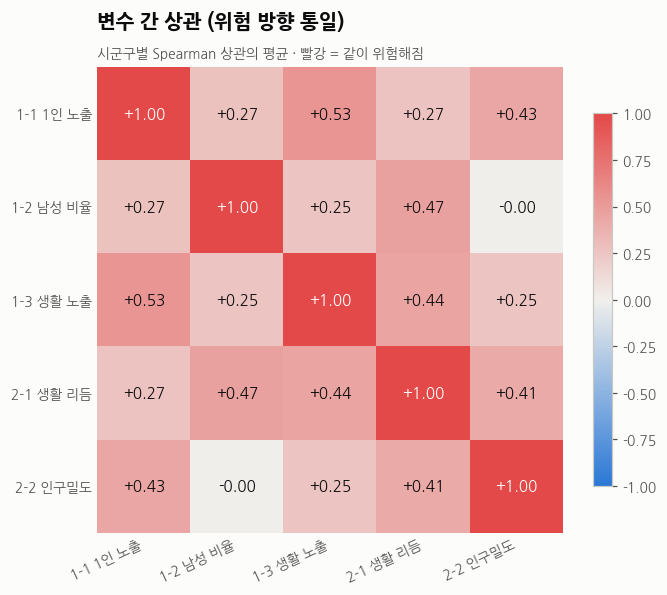

,강남구,춘천시,평균
1-1 1인 노출 × 1-2 남성 비율,-0.250,0.800,0.270
1-1 1인 노출 × 1-3 생활 노출,0.310,0.760,0.530
1-1 1인 노출 × 2-1 생활 리듬,0.140,0.390,0.270
1-1 1인 노출 × 2-2 인구밀도,0.240,0.620,0.430
1-2 남성 비율 × 1-3 생활 노출,-0.040,0.530,0.250
1-2 남성 비율 × 2-1 생활 리듬,0.310,0.620,0.470
1-2 남성 비율 × 2-2 인구밀도,-0.730,0.730,-0.000
1-3 생활 노출 × 2-1 생활 리듬,0.630,0.260,0.440
1-3 생활 노출 × 2-2 인구밀도,0.150,0.350,0.250
2-1 생활 리듬 × 2-2 인구밀도,-0.040,0.860,0.410


In [29]:
# 시군구 내 순위상관 (Spearman) - 위험 방향으로 부호를 맞춘 뒤 두 시군구 평균
risk_dir = feat[VARS] * np.where([RISK_UP[k] for k in VARS], 1, -1)
corr_sgg = {nm: g.corr(method='spearman') for nm, g in risk_dir.groupby(feat.SGG_NM)}
corr = sum(corr_sgg.values()) / len(corr_sgg)

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap=DIV)
ax.set_xticks(range(5), [SHORT[k] for k in VARS], rotation=25, ha='right'); ax.set_yticks(range(5), [SHORT[k] for k in VARS])
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{corr.iloc[i, j]:+.2f}', ha='center', va='center', fontsize=10,
                color='white' if abs(corr.iloc[i, j]) > 0.7 else INK)
ax.set_title('변수 간 상관 (위험 방향 통일)'); subtitle(ax, '시군구별 Spearman 상관의 평균 · 빨강 = 같이 위험해짐')
ax.grid(False); ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8); plt.show()

# 시군구별로 따로 보기
pairs = [(a, b) for i, a in enumerate(VARS) for b in VARS[i + 1:]]
pd.DataFrame({nm: [c.at[a, b] for a, b in pairs] for nm, c in corr_sgg.items()},
             index=[f'{SHORT[a]} × {SHORT[b]}' for a, b in pairs]).assign(평균=lambda d: d.mean(axis=1)).round(2)

**📌 해석** (위험 방향 통일: 양수 = 같이 위험해짐)
- 두 시군구 평균 상관은 **−0.00 \~ +0.53** → 서로 반대로 움직여 위험이 상쇄되는 변수가 없다 (1차 모델의 주간·주말 활력을 교체한 이유)
- **춘천은 모든 쌍이 +0.26 \~ +0.86** → 외곽 면 지역에서 다섯 위험이 함께 높아진다 (생활 리듬 × 인구밀도 +0.86, 1인 노출 × 남성 비율 +0.80)
- **강남은 방향이 갈린다**: 남성 비율 × 인구밀도 −0.73 (남성 비율이 높은 동이 오히려 밀도가 높음), 1인 노출 × 남성 비율 −0.25 → 두 지역을 평균하면 0 근처가 되는 쌍
- 강남에서 가장 강한 관계는 **생활 노출 × 생활 리듬 +0.63** → 5060이 덜 보이는 동이 낮에만 사람이 몰리는 업무지구형
- 👉 춘천에서는 변수들이 사실상 한 방향(외곽 면)을 가리키고, 강남에서는 변수마다 다른 동을 가리킨다 → 변수 하나가 아니라 **여러 변수를 축으로 묶어** 군집하는 근거

### 8-3. 동별 위험 프로파일 (5개 변수)

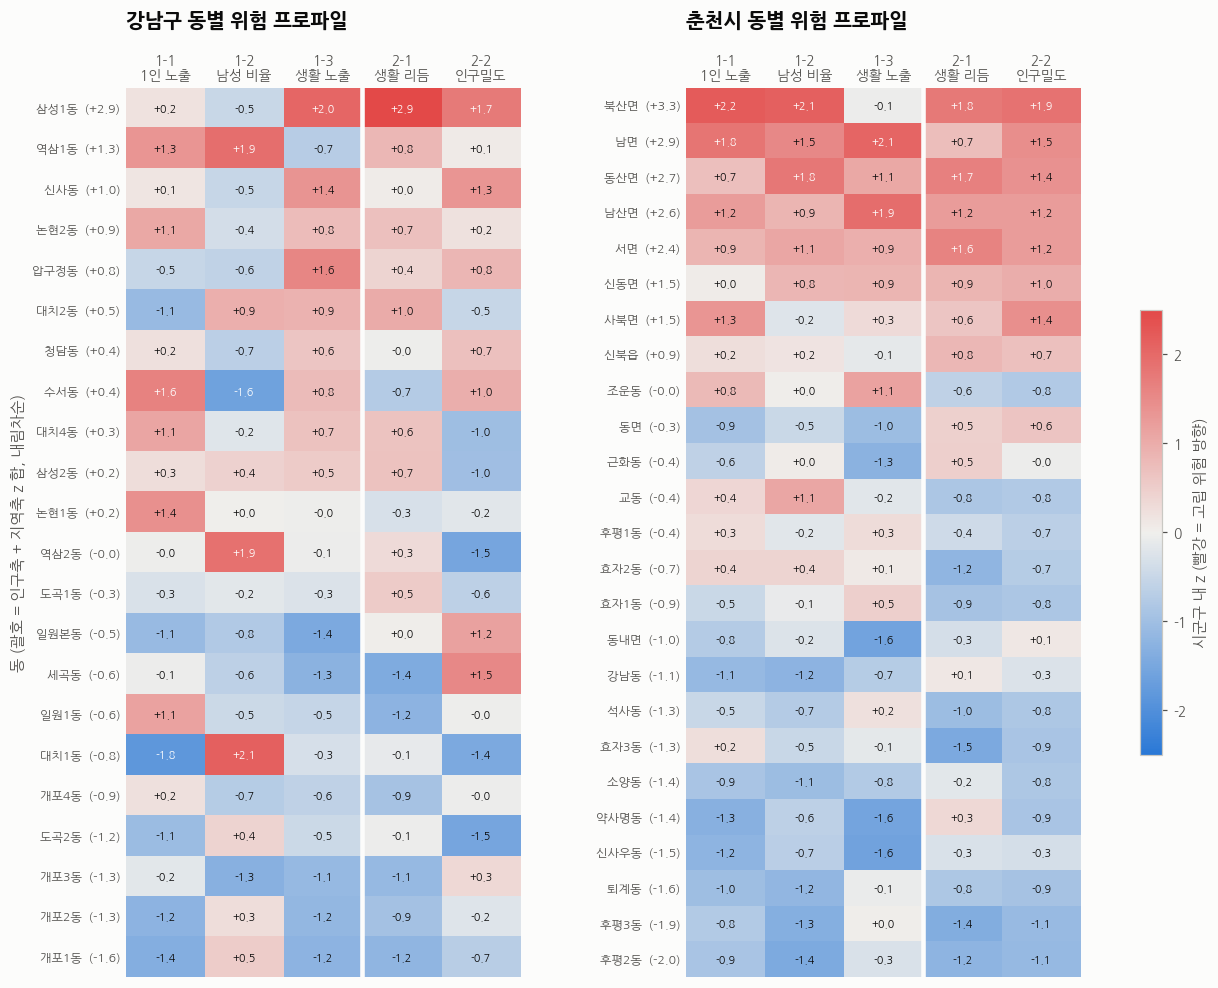

종합(인구축 + 지역축) 상위 5개 동
  강남구: 삼성1동(+2.9), 역삼1동(+1.3), 신사동(+1.0), 논현2동(+0.9), 압구정동(+0.8)
  춘천시: 북산면(+3.3), 남면(+2.9), 동산면(+2.7), 남산면(+2.6), 서면(+2.4)


In [30]:
# 시군구 내 z-score (위험 방향 통일, 인구밀도는 log 후 표준화) → 축 점수 = 축 변수 평균, 종합 = 인구축 + 지역축
ZR = pd.DataFrame({k: feat.groupby('SGG_CD')[k].transform(lambda s: (s - s.mean()) / s.std()) * (1 if RISK_UP[k] else -1)
                   for k in VARS})
ZR['POP_DENSITY'] = feat.groupby('SGG_CD').POP_DENSITY.transform(lambda s: -(np.log(s) - np.log(s).mean()) / np.log(s).std())
feat['Z_POP'], feat['Z_REG'] = ZR[POP_AX].mean(axis=1), ZR[REG_AX].mean(axis=1)
feat['Z_TOTAL'] = feat.Z_POP + feat.Z_REG

fig, axes = plt.subplots(1, 2, figsize=(14, 10.5), gridspec_kw={'wspace': 0.42})
for ax, nm in zip(axes, REGIONS):
    idx = feat[feat.SGG_NM == nm].sort_values('Z_TOTAL', ascending=False).index
    r = ZR.loc[idx, VARS]
    im = ax.imshow(r, cmap=DIV, vmin=-2.5, vmax=2.5, aspect='auto')
    for yi, row in enumerate(r.values):
        for xi, v in enumerate(row):
            ax.text(xi, yi, f'{v:+.1f}', ha='center', va='center', fontsize=7, color='white' if abs(v) > 1.6 else INK)
    ax.set_xticks(range(5), [SHORT[k].replace(' ', '\n', 1) for k in VARS], fontsize=9)
    ax.set_yticks(range(len(r)), [f'{n}  ({t:+.1f})' for n, t in zip(feat.loc[idx, 'EMD_NM'], feat.loc[idx, 'Z_TOTAL'])], fontsize=8)
    ax.xaxis.tick_top(); ax.grid(False); ax.tick_params(length=0)
    ax.axvline(2.5, color=SURF, lw=3)
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_title(f'{nm} 동별 위험 프로파일', pad=40)
axes[0].set_ylabel('동 (괄호 = 인구축 + 지역축 z 합, 내림차순)')
fig.colorbar(im, ax=axes, shrink=0.5, label='시군구 내 z (빨강 = 고립 위험 방향)')
plt.show()

print('종합(인구축 + 지역축) 상위 5개 동')
for nm in REGIONS:
    g = feat[feat.SGG_NM == nm].nlargest(5, 'Z_TOTAL')
    print(f'  {nm}:', ', '.join(f'{n}({v:+.1f})' for n, v in zip(g.EMD_NM, g.Z_TOTAL)))

**📌 해석** (빨강 = 고립 위험 방향, 왼쪽 3열 = 인구축, 오른쪽 2열 = 지역축)
- **춘천 상위**: 북산면(+3.3)·남면(+2.9)·동산면(+2.7)·남산면(+2.6)·서면(+2.4) → **외곽 면 지역은 다섯 변수가 대부분 빨강**. 그다음 신동면·사북면(+1.5), 신북읍(+0.9)
- **강남 상위**:
  - 삼성1동(+2.9): 생활 리듬 +2.9·생활 노출 +2.0·인구밀도 +1.7 → **지역축이 위험을 이끄는 업무지구**
  - 역삼1동(+1.3): 남성 비율 +1.9·1인 노출 +1.3 → **인구축이 위험을 이끔**
  - 신사동(+1.0): 생활 노출 +1.4·인구밀도 +1.3
- 수서동은 1인 노출 +1.6이지만 남성 비율 −1.6 → **여성 중장년 1인 가구형** (합계 +0.4)
- 저위험: 춘천 후평2·3동·퇴계동, 강남 개포1\~3동 → 고밀도 아파트 단지
- 👉 이 종합 점수(인구축 z + 지역축 z)는 `Clustering` 군집의 입력과 같다. 상위 10개 동 = 춘천 면 7개(북산·남·동산·남산·서·신동·사북면) + 강남 삼성1동·역삼1동·신사동
  - 위험도 5단계는 변수별 1\~5점 단계 점수의 합으로 매기므로 순위가 조금 다르다 (5단계에는 신사동 대신 논현2동이 들어감, 두 점수의 순위상관 0.97)

### 8-4. 인구축 두 변수: 1-1 × 1-2

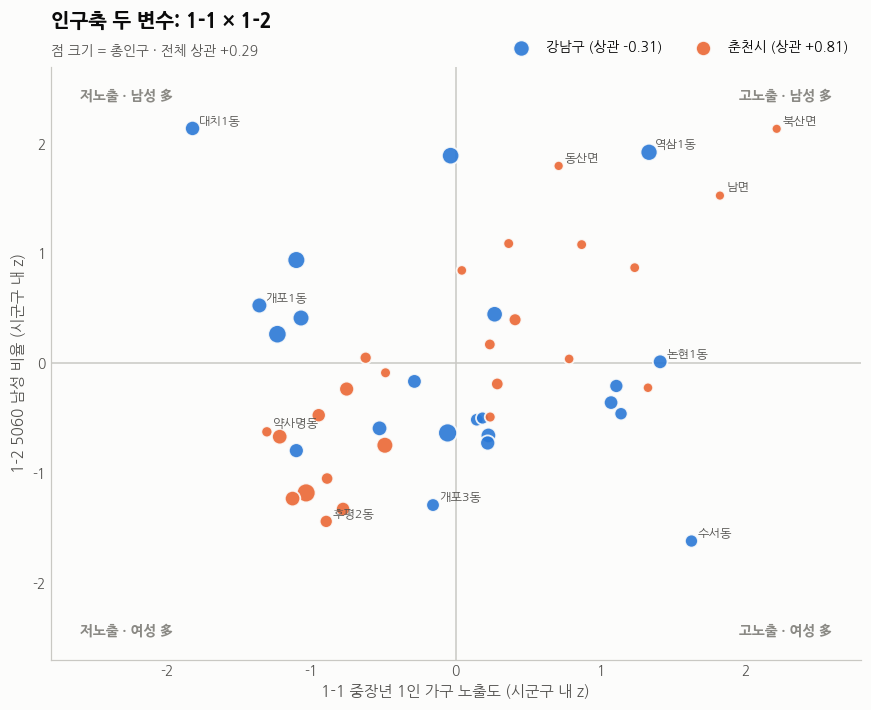

SGG_NM,강남구,춘천시,합계
QUADRANT,,,
고노출·남성多,3,10,13
고노출·여성多,8,3,11
저노출·남성多,6,1,7
저노출·여성多,5,11,16
합계,22,25,47


In [31]:
# 시군구 내 표준화 (z-score) → 지역 차이 제거 후 두 변수의 관계 (사분면 프로파일)
Z = [f'{k}_Z' for k in KEY]
feat[Z] = feat.groupby('SGG_CD')[KEY].transform(lambda x: (x - x.mean()) / x.std())

r_all = feat[Z[0]].corr(feat[Z[1]])
r_sgg = {nm: g[Z[0]].corr(g[Z[1]]) for nm, g in feat.groupby('SGG_NM')}

fig, ax = plt.subplots(figsize=(9.5, 7))
ax.axhline(0, color='#c9c8c3', lw=1); ax.axvline(0, color='#c9c8c3', lw=1)
for nm in REGIONS:
    g = feat[feat.SGG_NM == nm]
    ax.scatter(g[Z[0]], g[Z[1]], s=40 + g.TOT_POP_CNT / 400, color=C[nm], edgecolor=SURF, linewidth=1.2,
               alpha=0.9, label=f'{nm} (상관 {r_sgg[nm]:+.2f})', zorder=3)
    label_extremes(ax, g, Z[0], Z[1], n=2)
for (x, y, txt) in [(1, 1, '고노출 · 남성 多'), (-1, 1, '저노출 · 남성 多'), (-1, -1, '저노출 · 여성 多'), (1, -1, '고노출 · 여성 多')]:
    ax.text(2.6 * x, 2.5 * y, txt, ha='right' if x > 0 else 'left', va='top' if y > 0 else 'bottom',
            fontsize=9, color=MUTED, fontweight='bold')
ax.set_xlim(-2.8, 2.8); ax.set_ylim(-2.7, 2.7)
ax.set_xlabel('1-1 중장년 1인 가구 노출도 (시군구 내 z)'); ax.set_ylabel('1-2 5060 남성 비율 (시군구 내 z)')
ax.set_title('인구축 두 변수: 1-1 × 1-2'); subtitle(ax, f'점 크기 = 총인구 · 전체 상관 {r_all:+.2f}')
ax.legend(loc='lower right', bbox_to_anchor=(1, 1.0), ncol=2); ax.grid(False); ax.tick_params(length=0); plt.show()

quad = np.select([(feat[Z[0]] >= 0) & (feat[Z[1]] >= 0), (feat[Z[0]] >= 0) & (feat[Z[1]] < 0),
                  (feat[Z[0]] < 0) & (feat[Z[1]] >= 0)], ['고노출·남성多', '고노출·여성多', '저노출·남성多'], '저노출·여성多')
feat['QUADRANT'] = quad
pd.crosstab(feat.QUADRANT, feat.SGG_NM, margins=True, margins_name='합계')

**📌 해석** (점 크기 = 동 총인구, 사분면 = 시군구 평균 대비 위치)
- 시군구 내 표준화 후 1-1·1-2의 전체 상관은 **+0.29**로 낮다 → 두 변수를 함께 군집에 쓸 수 있다
- 다만 지역별로 관계가 **정반대**다
  - **춘천 +0.81**: 1인 노출이 높은 동은 남성 비율도 높다 (외곽 면 지역). 춘천에서는 두 변수가 사실상 **같은 축**
  - **강남 −0.31**: 1인 노출이 높은 동(수서동·일원1동 등)은 오히려 여성이 많다
- 사분면 분포
  - **고노출·남성多 13개 동** (춘천 10, 강남 3): 북산면·남면·동산면·역삼1동 → 중장년 남성 1인 가구 고위험형
  - **고노출·여성多 11개 동** (강남 8, 춘천 3): 수서동·논현2동 등 → 중장년 여성 1인 가구형
  - **저노출 23개 동**: 상대적 저위험

## 정리
**클러스터링 입력 (행정동 단위, `modeling/Clustering.ipynb`와 동일 정의, 시군구 내 z-score)**
| 축 | 파생변수 | 핵심 발견 | 위험 쪽 동 (예) |
|---|---|---|---|
| 인구축 | 1-1 `HH1_EXPO_5060` | 5060 비중과 1인 가구 비율은 상관이 약해 결합 필요 | 춘천 북산면·남면, 강남 수서동 |
| 인구축 | 1-2 `MALE_SHARE_5060` | 춘천 면 지역은 5060 남성 비율 최대 60% | 춘천 북산면·동산면, 강남 대치1동·역삼1동 |
| 인구축 | 1-3 `VISIBLE_IDX_50P` | 춘천 5060은 주민 비중보다 거리에서 덜 보임 (중앙값 0.87) | 춘천 남면·남산면, 강남 삼성1동 |
| 지역축 | 2-1 `TIME_ENTROPY` | 절댓값 차이는 작지만 업무지구·외곽 면은 특정 시간대에 집중 | 강남 삼성1동, 춘천 북산면·서면 |
| 지역축 | 2-2 `POP_DENSITY` | 춘천 안에서만 4,000배 이상 차이 → log 후 표준화 | 춘천 외곽 면, 강남 삼성1동·세곡동 |

- 위험 방향을 맞추면 다섯 변수 모두 상관 0 이상 → 함께 군집에 쓸 수 있음. 춘천은 한 방향, 강남은 변수마다 다른 동을 가리킴
- 종합(인구축 z + 지역축 z) 상위: 춘천 외곽 면 7개 + 강남 삼성1동·역삼1동·신사동 (`Clustering` 위험도 5단계는 단계 점수 합 기준이라 신사동 대신 논현2동)

**카드 소비 (EDA 전용, 시군구 단위)**
- 5060은 관계형 소비가 줄고 단독생계형 소비가 늘어나는 전환기. 춘천 5060의 관계형 소비가 강남보다 낮음
- **60대 여성의 관계형 소비가 가장 낮음** (금액·건수 모두). 금액 기준의 남성 우위는 결제자 효과로 보임
- 5060 특화 업종은 생활 유지형(장례·인테리어·LPG·농수산물), 비특화 업종은 여가·문화형

**유동인구 (EDA 전용, 행정동 × 월)**
- 강남은 연휴(8·10월), 춘천은 9월 정점 후 겨울(10\~12월)에 유동인구 감소 → 지역별로 외부 접촉이 줄어드는 시기가 다름
- 주말/평일 비율: 강남 오피스 동(역삼1·삼성2·논현2동)과 춘천 도심(교동·효자2동)은 주말 공동화, 춘천 외곽 면은 주말 외지인 유입
- 연령 구간이 `60세 이상`으로 묶여 있어 유동인구의 5060 값은 70대 이상을 포함한 과대 추정치 → 1-3에서는 주민 60세+ 중 60대 비율로 보정
- 유동인구 규모는 상권·업무 기능을 반영하므로, 파생변수는 비율(1-3)·분포(2-1)로 만들었음

**주의할 점**
- 강남 위험 상위(삼성1동·역삼1동)는 업무지구 효과(낮 시간 집중, 청년 1인 가구)가 섞였을 수 있음
- 다섯 변수 모두 비율·밀도라 소규모 동(북산면 935명, 남면 1,017명)은 값이 불안정
- 1-3의 60대 추정은 유동인구의 60세 이상 연령 구성이 주민과 같다고 가정